# Rewards and contract types for the learned controllers

`FIGURES_RL.ipynb` (section 6) ended on a diagnosis: on SI the learned controllers leave the
**contract line** of the bill almost untouched. The whole-year MILP takes 54 EUR/a off the
standing charge by lowering the agreed power, the peak-shaving rules take 31–36, the learned
controllers 10–13 — and the reason was in the training loop, not in the learners. The reward,
the validation measure and every tuning choice priced `price_interval`'s *variable* part only
(energy + excess power), against the no-battery contract. The standing charge, which the
household's own peaks re-agree every month, was invisible.

This notebook presents what was built to fix that (`rl_reward.py`, driven by
`run_rl_contract.py`), extends the learned controllers to the SI contracts the study never
ran, and answers four questions on the 30 study households and the panel's `fc_h24` features:

1. **Does paying the agent for the contract help?**
2. **Should AU, and each kind of SI contract, have its own reward function?**
3. **Do separately trained models for each contract type help?**
4. **Do the hyperparameters survive the new reward?** (`rl_hpo`, searched again under it)

### "Contract type" means two things, and both are here

| family | types | what differs |
|---|---|---|
| **price list** (the supplier's) | **dynamic** — SIPX hour by hour, the study's · **active** — four posted prices by time of day and season · **single-tariff** — one price in, one out | the *energy* line: 347, 827 and 619 EUR/a on the same households |
| **agreed-power rule** | **re-agreed monthly**, the study's · **signed** (a fixed number) · **rolling 12 months** | the *standing charge*: whether, and for how long, a shaved peak is paid for again |

The two cross at the study's own contract (dynamic price, agreed power re-agreed monthly).
The price lists are the contract types the request meant, and they were not implemented in
this study: `build_study_env` pinned GEN-I Dinamični. They now run end to end — rules, MILP
and learners — through the same tariff code (`hs.build_study_env(paket_id=)`), each as GEN-I's
own self-supply list. The agreed-power rules were built first, on a misreading of the
request; they are kept (section 5) because they are what decides *which reward* a contract
needs.

### The answers

| | |
|---|---|
| **1. Contract charge** | Yes for **RL**, no for the clone. On the study's contract the DQN trained with the contract charge saves **+12.6 EUR/a** more than the panel's DQN (95 % CI 6.4–19.0, 20 of 30 households, p_holm 0.004): 59.7 against 47.0, the best learned controller on that contract. It takes 32 EUR/a off the standing charge where it took 12. On the single-tariff list it adds +6.3 (p_holm 0.02); on the active list nothing (+0.5) — there the energy line is five times the contract line and the agent trades one for the other. **IL** and **IL+RL** do not move on any contract. (These are seed 0, as the panel is; over three seeds the gain on the study's contract is +7.9 — answer 4.) |
| **2. A reward per bill** | Yes. The settled part of the reward follows the price list by itself — it is the arm's own settlement. What has to be chosen is the contract part, and the dividing line is **whether the dispatch moves the contract**: on a signed contract a contract-charge model loses 9.3 EUR/a to that contract's own (p_holm 0.001). AU has no capacity charge and keeps the energy reward it always had. |
| **3. A model per contract type** | **Across price lists: yes, decisively.** A model run on a price list it was not trained on loses most of what a battery is worth there: the dynamic-list clone on the active list saves 166 EUR/a where the active-list clone saves 277 (−111, 30 of 30 households); the active-list clone on the dynamic list 34 against 54; a single-tariff model on the dynamic list almost nothing. One model per price list averages 131–137 EUR/a over the three lists, the best single model 113–126. **Across agreed-power rules: no** — there two rewards are enough, and one model of each. |
| **4. Hyperparameters** | **Yes — the search found nothing better.** 40 trials per learner under the contract reward, the best refined over three seeds: on validation they are within noise of the panel's settings (RL +0.9, IL+RL +3.2 EUR/a; p 0.95 and 0.46), and on the test year the tuned RL settings are *worse* by 10.2 EUR/a (6 of 30 households better, p < 0.001) and the tuned fine-tune is level (+1.1). The panel's settings stay. The same three seeds re-measure answer 1: the contract charge is worth **+7.9 EUR/a** to RL averaged over three seeds (CI 3.2–12.6, p_holm 0.02; +12.2, +7.8 and +3.8 by seed) — positive in every seed, and smaller than seed 0's +12.6. |

**Where the learned controllers stand** changes completely with the price list. On the
**active** list they are the best controllers the study has: 274–277 EUR/a, **60 EUR/a ahead
of the best rule** (29–30 of 30 households) and 83–84 % of the whole-year optimum. On the
dynamic and single-tariff lists they are still behind `self-consumption + peak shaving`
(by 12.5 and 13.4 EUR/a at best).

Nothing here was chosen on the test year. The reward's settings were decided on held-out
validation weeks (section 2) and came out as *the bill as it is*.

### What was changed in the code

- **`rl_reward.py`** (new): one reward function per bill. The contract charge is what an
  interval's draw adds to the standing charge of the pool the next agreed power is read
  from — computed from `si_moc`'s own statistic and the real prorated standing charge, so it
  telescopes to the invoice line (`test_rl_reward` checks it against what the environment
  bills, to the cent). During training the contract is **re-agreed from the agent's own
  peaks** at every validation, as `run_policy` re-agrees it at scoring time; validation
  itself prices the contract on the held-out weeks.
- **`hems_study.build_study_env(paket_id=, contracted_power_kw=, agreed_power=)`**: the
  environment factory takes the supplier's price list and the agreed-power rule. Both
  default to the study's, and the study's environment is exactly what it was.
- **`rl_control.py`**: `train_dqn(reward_fn=)` / `train_bc(reward_fn=)`, contract features
  (`FeatureSpec.contract_features`), `LearnedPolicy(tracker_factory=)`. All inert by default:
  the panel's 1,260 results, the pooled runs and the earlier search keep their digests, and
  the two legacy rewards train bit for bit as the old loop does (tested).
- **`run_rl_contract.py`** (new): `refs` (rules and MILP per contract), `tune` (validation
  only), `train`, `retrain` (unsettled runs at 1M steps, the panel's protocol), `cross`
  (every model on every contract type of its family), `report`. Resumable, digest-cached.
- **`rl_hpo.py`**: a study can be created under `reward="contract"`
  (`run_rl_hpo.py all --reward contract`); the panel's studies are untouched.
- **Scoring is unchanged**: `Rule_Based_Control.run_policy`, the arm's settlement, the
  contract's own fixed point. The reward is the training signal only.

The savings below are on the **total bill**: `Cost_EUR_Closed` plus the standing charge of the
contract the controller ends up on, against the same household's no-battery bill under the
same contract. One seed (0) unless a section says otherwise, as in the panel.

To reproduce: `cd Main && python3 run_rl_contract.py refs|tune|train|retrain|cross --jobs 12 --quiet`
(each until it prints `ALL DONE`), `python3 run_rl_hpo.py all --reward contract --jobs 12`,
then re-run this notebook.

In [1]:
import importlib

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import hems_study as hs
import figure_style as fs
import rl_reward as rr
import run_rl_benchmark as rb
import run_rl_contract as rc
import rl_hpo as hpo
hs, fs, rr, rb, rc, hpo = (importlib.reload(m) for m in (hs, fs, rr, rb, rc, hpo))

import Plotting_Functions as pf
pf = importlib.reload(pf)
pf.use(subdir="hems", titles=False)
from Plotting_Functions import INK, INK_2, MUTED, SURFACE, SERIES, EUR, finish

# Two families of contract type, crossing at the study's own contract
# ("monthly": the dynamic price list, agreed power re-agreed monthly).
FAMILIES = {"price": rr.PRICE_TYPES, "power": rr.CONTRACT_TYPES}
FAMILY_NAME = {"price": "price list", "power": "agreed-power rule"}
LABEL = {"price": rr.PRICE_LABEL,
         "power": {c: rr.CONTRACT_LABEL[c] for c in rr.CONTRACT_TYPES}}
SHORT = {"price": {"monthly": "dynamic", "active": "active", "single": "single-tariff"},
         "power": {"fixed": "signed", "monthly": "monthly", "annual": "12-month"}}
STUDY = rr.REFERENCE_CONTRACT
# A contract type's name on its own, outside a family: the study's contract is
# named by both of its halves.
TYPE_NAME = {**rr.CONTRACT_LABEL, **rr.PRICE_LABEL,
             STUDY: "the study's (dynamic price, re-agreed monthly)"}
METHODS = ("bc", "bc_dqn", "dqn")
METHOD_NAME = {"bc": "IL", "bc_dqn": "IL+RL", "dqn": "RL"}
UNIT = hs.money("SI", "year")

# What a colour MEANS here. A contract type is a hue; a bill line is a hue of
# its own; a learned controller keeps the family marker it has in FIGURES_RL,
# filled when it was paid for the contract and hollow when it was not.
CONTRACT_COLOR = {"fixed": SERIES[2], "monthly": fs.TARIFF_COLOR["SI"],
                  "annual": SERIES[3], "active": SERIES[0], "single": SERIES[2]}
LINE_COLOR = {"energy": SERIES[0], "power": SERIES[3], "standing": SERIES[1],
              "closeout": MUTED}
LINE_NAME = {"energy": "energy", "power": "excess power",
             "standing": "standing charge on the agreed power",
             "closeout": "terminal-SOC close-out"}
ARM_NAME = {"excess": "settled bill only", "contract": "+ contract charge"}
ARM_SHORT = {"excess": "settled bill", "contract": "+ contract charge"}


def learned_name(controller):
    method, arm = controller.split(":")
    return f"{METHOD_NAME[method]}, {ARM_NAME[arm]}"


def label(controller):
    if ":" in controller:
        return learned_name(controller)
    return fs.tick_label(controller, {c: hs.controller_label(c, 48, n_sim=365)
                                      for c in [controller]})


def family_key(controller):
    return controller.split(":")[0] + "_fc_h24" if ":" in controller else controller


SUMMARY = {}          # contract type -> its ranking table (section 3 on)
RANK = rc.ranking_frame()
RES = rc.load_results()
CROSS = rc.load_cross()
TUNE = rc.tune_frame()
N_HH = RANK.groupby("contract")["ident"].nunique().to_dict()
print("households per contract type:", N_HH)
print("trained runs:", RES.groupby(["contract", "arm", "method"]).size().unstack().to_string())
print("cross-evaluations:", len(CROSS), "  tuning runs:", len(TUNE))

households per contract type: {'active': 30, 'annual': 30, 'fixed': 30, 'monthly': 30, 'single': 30}
trained runs: method             bc  bc_dqn  dqn
contract arm                      
active   contract  30      30   30
         excess    30      30   30
annual   contract  30      30   30
         excess    30      30   30
fixed    excess    30      30   30
monthly  contract  30      30   30
         excess    30      30   30
single   contract  30      30   30
         excess    30      30   30
cross-evaluations: 2790   tuning runs: 300


## 1. Five contracts, five bills

The same 30 households, no battery, billed under each contract type — first the three price
lists, then the three agreed-power rules. Below each figure, what the whole-year MILP takes
off each line: the most a battery can win there, and from which line.

**By price list** the energy line is what moves: 347 EUR/a on the dynamic list, 619 on the
single-tariff one, 827 on the active one. So does what a battery can do about it. On the
active list the optimum takes **278 EUR/a off energy** — five times what it takes on the
other two (52 and 66) — because four posted prices 15 cents apart are a spread a battery can
trade every working day. The standing-charge line is worth about the same on all three
(47–54): the agreed-power rule is the same.

**By agreed-power rule** it is the reverse: energy is identical, and the standing charge is
**0** on the signed contract and **half the optimum** on the other two.

Those two tables are the case for separate reward functions. The price list changes what the
energy line pays for, and the reward follows it without being told — its settled part is the
arm's own settlement. The agreed-power rule changes whether there is a contract line to pay
for at all, and that part has to be chosen.

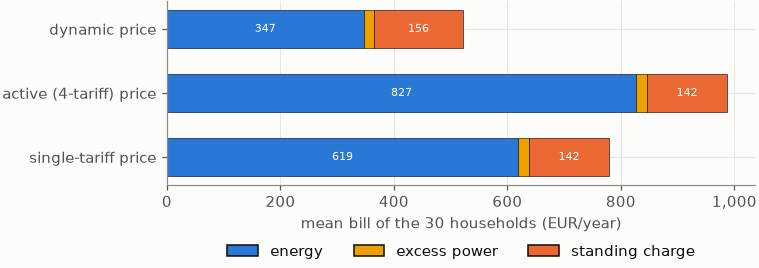

by price list: what the whole-year MILP takes off each line, mean EUR/year
                         energy  power  standing  closeout  total
dynamic price              52.2    1.9      54.0       0.2  108.3
active (4-tariff) price   278.0    4.4      47.4       0.0  329.8
single-tariff price        65.5    2.5      52.8       0.4  121.3 



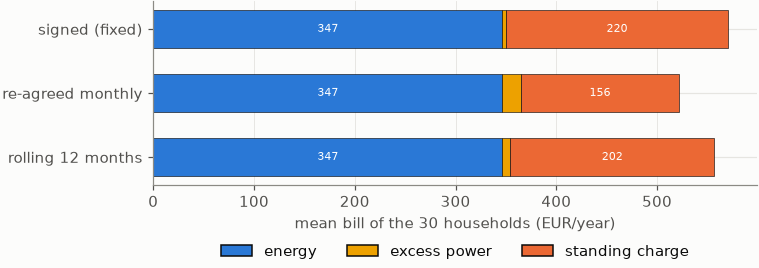

by agreed-power rule: what the whole-year MILP takes off each line, mean EUR/year
                   energy  power  standing  closeout  total
signed (fixed)       52.8    2.9       0.0       0.3   55.9
re-agreed monthly    52.2    1.9      54.0       0.2  108.3
rolling 12 months    52.6    2.8      45.6       0.3  101.3 

AU, for comparison -- one bill line a dispatch moves (energy), one reward (`AUEnergyReward`),
the panel's models unchanged; mean saving on the bill, AUD/year:
method
IL       261.4
IL+RL    255.3
RL       235.5


In [2]:
# The no-battery bill of the 30 households, by line, under each contract type:
# first across the price lists, then across the agreed-power rules.
refs = rc.load_refs()
for fam, types in FAMILIES.items():
    bill = (refs[refs.controller == "no_battery"]
            .groupby("contract")[["energy_eur", "power_eur", "fixed_eur"]].mean()
            .reindex(types))
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.36))
    y = np.arange(len(types))
    left = np.zeros(len(types))
    parts = [("energy", bill.energy_eur.to_numpy()),
             ("power", bill.power_eur.to_numpy()),
             ("standing", bill.fixed_eur.to_numpy())]
    for name, vals in parts:
        ax.barh(y, vals, left=left, color=LINE_COLOR[name], edgecolor=INK, lw=0.4,
                height=0.6)
        for yi, (l, v) in enumerate(zip(left, vals)):
            if v > 0.05 * bill.sum(axis=1).max():
                ax.text(l + v / 2, yi, f"{v:,.0f}", ha="center", va="center",
                        fontsize=7.5, color="white")
        left += vals
    ax.set_yticks(y)
    ax.set_yticklabels([LABEL[fam][c] for c in types])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Patch(facecolor=LINE_COLOR[n], edgecolor=INK,
                             label={"energy": "energy", "power": "excess power",
                                    "standing": "standing charge"}[n])
                       for n, _ in parts], where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI: the no-battery bill by {FAMILY_NAME[fam]}",
           xlabel=f"mean bill of the 30 households ({UNIT})", ylabel="")
    pf.show(fig, f"rlc_bill_by_{fam}")

    print(f"by {FAMILY_NAME[fam]}: what the whole-year MILP takes off each line, mean {UNIT}")
    t = (RANK[RANK.controller == "milp_full"]
         .groupby("contract")[["energy", "power", "standing", "closeout", "total"]]
         .mean().reindex(types))
    t.index = [LABEL[fam][c] for c in t.index]
    print(t.round(1).to_string(), "\n")

panel = rb.load_results()
au = panel[(panel.tariff == "AU") & (panel.variant == "fc_h24")]
print("AU, for comparison -- one bill line a dispatch moves (energy), one reward "
      "(`AUEnergyReward`),\nthe panel's models unchanged; mean saving on the bill, "
      + hs.money("AU", "year") + ":")
print(au.groupby("method")["saving"].mean().rename(index=METHOD_NAME).round(1).to_string())

## 2. Choosing the reward's settings — validation only

The contract charge has no free coefficient: it is the standing charge. What it leaves open
is how an *episode* of one or two weeks should be charged for a contract that only whole
billing periods decide, and that was settled on the validation weeks, by `run_rl_contract.py tune`
on the study's contract, before any model in the next sections was scored. Each row below is
one departure from the default, paired by household, positive = cheaper on validation than
the default.

Three things were measured on the way, each of which changed the design:

- **The validation measure has to carry the contract's *level*.** The first held-out measure
  charged a week for what its peaks *added* to the month's pool. On it the whole-year MILP
  scored no better than a peak-shaving rule, because a profile shaved to one flat line adds
  nothing week by week whatever the line is. The measure now also bills each held-out week
  its time-share of the standing charge the rest of the pool sets.
- **Pricing an episode into the agent's own past is a trap.** Charging an episode's draws
  against the rest of the month *as the agent last dispatched it* is the exact marginal cost —
  and it never pays an episode to go below peaks the agent left standing elsewhere. On a
  monthly contract the pool therefore opens **empty** with the episode, which is billed its
  time-share of the contract its own peaks set ("episode" pricing). The meter-pool
  alternative ("priced by the meter's pool") is the row that tests this.
- **The contract has to be the agent's own during training.** Charging the contract without
  re-agreeing it ("contract not re-agreed in training") is the one departure that is
  significantly worse for both learners.

Result: weights 0.5, 1 and 2 are indistinguishable (all p_holm ≥ 0.35), so the charge stays
at 1 — the bill, with no shaping coefficient to defend. Not re-agreeing the contract costs
5.3 EUR/a (IL+RL, p_holm 0.0005) and 3.9 (RL, p_holm 0.02) on validation. The meter-pool
pricing is worse by 2.4–3.5 EUR/a, not significantly after correction; "episode" is kept on
the argument above and because nothing favours the alternative.

`CONTRACT_TUNED` in the driver is therefore empty, and the same bill at weight 1 is what
every other contract type trains on.

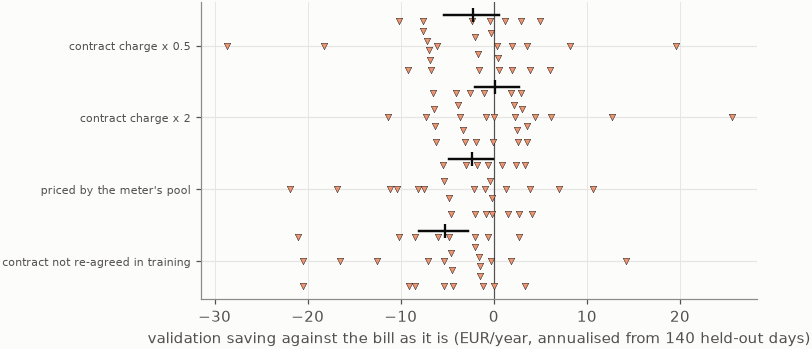

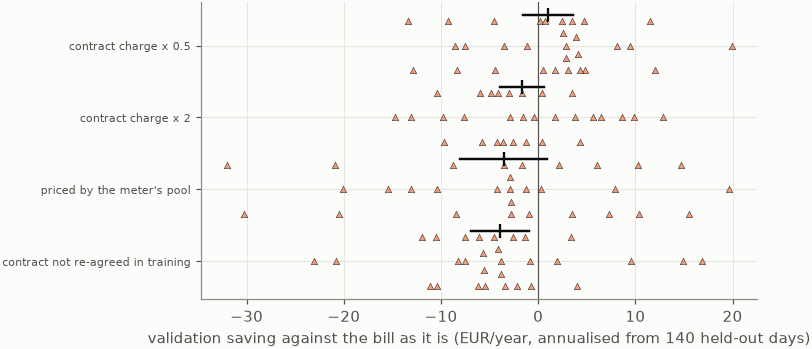

contract method                              point  n  mean  ci_lo  ci_hi  better      p  p_holm
 monthly  IL+RL              contract charge x 0.5 30 -2.28  -5.34   0.59      13 0.1772  0.3544
 monthly  IL+RL                contract charge x 2 30  0.15  -2.06   2.68      14 0.5291  0.5291
 monthly  IL+RL         priced by the meter's pool 30 -2.35  -4.80  -0.13      10 0.0961  0.2883
 monthly  IL+RL contract not re-agreed in training 30 -5.28  -8.01  -2.73       4 0.0001  0.0005
 monthly     RL              contract charge x 0.5 30  0.97  -1.61   3.61      20 0.4522  0.5316
 monthly     RL                contract charge x 2 30 -1.66  -3.92   0.63      11 0.1772  0.5316
 monthly     RL         priced by the meter's pool 30 -3.51  -8.10   0.95      11 0.1772  0.5316
 monthly     RL contract not re-agreed in training 30 -3.91  -6.87  -0.91       6 0.0054  0.0215

mean validation cost per grid point (EUR over the held-out days):
contract                 monthly        
method             

In [3]:
# VALIDATION ONLY -- no test-year number is read in this cell. Each grid point
# against the bill as it is (weight 1, the contract type's own pricing, the
# contract re-agreed during training), paired by household, on the held-out
# contract validation, annualised.
if TUNE.empty:
    print("no tuning runs on disk: `python3 run_rl_contract.py tune --jobs 12 --quiet`")
else:
    DAYS = sum(b - a for a, b in rb.VAL_BLOCKS)
    BASE = "weight1"
    POINT_NAME = {"weight1": "the bill as it is (weight 1)",
                  "weight0.5": "contract charge x 0.5",
                  "weight2": "contract charge x 2",
                  "pricingratchet_weight1": "priced by the meter's pool",
                  "self_consistent0_weight1": "contract not re-agreed in training"}
    TROWS = []
    for contract in sorted(TUNE.contract.unique()):
        for m in [m for m in METHODS if m in set(TUNE.method)]:
            g = TUNE[(TUNE.contract == contract) & (TUNE.method == m)]
            wide = g.pivot(index="ident", columns="tag", values="val_cost").dropna()
            if BASE not in wide:
                continue
            tags = [t for t in POINT_NAME if t in wide and t != BASE]
            fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.07 * len(tags)))
            ps = []
            for i, t in enumerate(tags):
                # A SAVING: positive = the grid point is cheaper on validation.
                d = (wide[BASE] - wide[t]).to_numpy() * 365.0 / DAYS
                r = hs.paired_comparison(wide, BASE, t)
                lo, hi = fs.boot_ci(d, stat=np.mean)
                ps.append(r["p_value"])
                TROWS.append({"contract": contract, "method": METHOD_NAME[m],
                              "point": POINT_NAME[t], "n": len(d), "mean": d.mean(),
                              "ci_lo": lo, "ci_hi": hi, "better": int((d > 0).sum()),
                              "p": r["p_value"]})
                col = fs.ctrl_color("SI", f"{m}_fc_h24")
                ax.scatter(d, i + fs.beeswarm(d), marker=fs.ctrl_marker(f"{m}_fc_h24"),
                           s=18, color=col, edgecolor=INK, lw=0.3, zorder=3)
                ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
                ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
            for row, p_h in zip(TROWS[-len(tags):], fs.holm(ps)):
                row["p_holm"] = p_h
            ax.axvline(0, color=INK_2, lw=0.8)
            ax.set_yticks(range(len(tags)))
            ax.set_yticklabels([POINT_NAME[t] for t in tags], fontsize=7.5)
            ax.invert_yaxis()
            ax.grid(axis="x", color=pf.GRID, lw=0.6)
            ax.set_axisbelow(True)
            finish(ax, title=f"SI {METHOD_NAME[m]}, {TYPE_NAME[contract]}: "
                             f"reward settings on validation",
                   xlabel=f"validation saving against the bill as it is ({UNIT}, "
                          f"annualised from {DAYS} held-out days)", ylabel="")
            pf.show(fig, f"rlc_tune_{contract}_{m}")
    TUNE_TABLE = pd.DataFrame(TROWS)
    with pd.option_context("display.width", 200):
        print(TUNE_TABLE.round({"mean": 2, "ci_lo": 2, "ci_hi": 2, "p": 4,
                                "p_holm": 4}).to_string(index=False))
    print("\nmean validation cost per grid point (EUR over the held-out days):")
    print(TUNE.pivot_table(index="tag", columns=["contract", "method"],
                           values="val_cost").round(2).to_string())

## 3. The contract charge on the study's own contract

Dynamic price, agreed power re-agreed monthly: the contract every arm of the study runs.
Three figures — every controller's saving on the total bill, what the contract charge adds
to each learner household by household, and where each controller's saving comes from.

Learned rows are filled when trained with the contract charge and hollow when trained on the
settled bill only. The hollow rows **are the panel's models**, re-scored rather than
re-trained (and checked against the panel's stored bill); the rules and the MILP reproduce
the SI reference arm's checkpoint (rules to the cent, the MILP to its solver gap).

- **RL gains +12.6 EUR/a** (20 of 30 households, p_holm 0.004) and becomes the best learned
  controller: 59.7, above the clone (54.5), nominally above the peak-shaving rule (53.5; 17
  of 30, not significant), below `self-consumption + peak shaving` (72.2) and the optimum
  (108.3).
- **The gain is the standing charge.** The DQN paid for the contract takes 32 EUR/a off it
  — what `self-consumption + peak shaving` takes (31) — up from 12, and gives back 5 on
  energy. What still separates it from that rule is the energy line: 28 against the rule's
  36 and self-consumption's 42. It cycles twice as much as the rules (146 EFC/a against
  72–75) to hold energy for peaks, and on a list whose prices barely move, cycling through
  the grid costs round-trip losses.
- **IL (−0.7) and IL+RL (−0.7) do not gain.** A clone has no reward; what the contract arm
  changes for it is its inputs — the contract threshold as a feature and the teacher's own
  contract during the walk — and neither helps it copy a perfect-foresight plan. The clone
  is the mirror image of the DQN: the best energy line of any learned controller (42) and
  almost no contract line (12–13).

So on this contract the two learners now fail on different lines, and neither fails on the
reward: RL is short on energy, the clone on the contract.

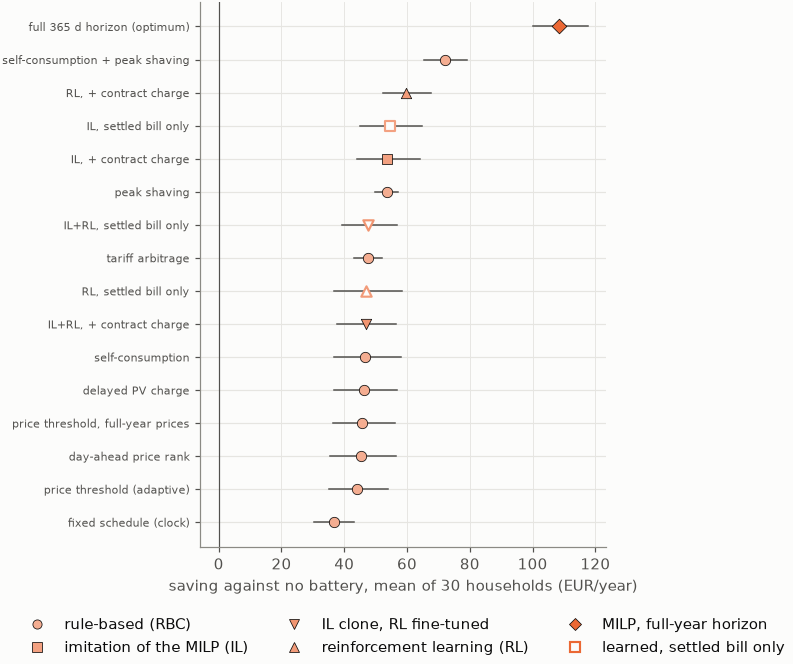


the study's (dynamic price, re-agreed monthly) -- saving on the total bill, EUR/year
                                    mean  ci_lo  ci_hi  median
full 365 d horizon (optimum)       108.3  100.2  117.5   103.9
self-consumption + peak shaving     72.2   65.4   79.2    69.4
RL, + contract charge               59.7   52.3   67.5    56.6
IL, settled bill only               54.5   45.1   64.7    53.6
IL, + contract charge               53.7   44.2   64.1    50.5
peak shaving                        53.5   49.6   57.1    55.2
IL+RL, settled bill only            47.5   39.3   56.7    44.3
tariff arbitrage                    47.5   43.2   51.9    44.6
RL, settled bill only               47.0   36.7   58.3    38.9
IL+RL, + contract charge            46.8   37.8   56.6    39.8
self-consumption                    46.8   36.9   57.9    39.5
delayed PV charge                   46.1   36.6   56.9    38.8
price threshold, full-year prices   45.7   36.3   56.2    38.3
day-ahead price rank            

In [4]:
# One figure per contract type: every controller's saving on the TOTAL bill
# (the closed bill plus the standing charge of the contract it ends up on),
# against that contract's own no-battery row. Mean and bootstrap 95 % CI over
# the households; the specialist reward's rows are filled, the other hollow.
for contract in [STUDY]:
    sub = RANK[(RANK.contract == contract) & (RANK.controller != "no_battery")]
    wide = sub.pivot(index="ident", columns="controller", values="total").dropna(axis=1)
    order = wide.mean().sort_values().index.tolist()
    rows = []
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.042 * len(order)))
    for i, c in enumerate(order):
        v = wide[c].to_numpy()
        lo, hi = fs.boot_ci(v, stat=np.mean)
        learned = ":" in c
        special = learned and c.endswith(":" + rc.SPECIALIST[contract])
        col = fs.ctrl_color("SI", family_key(c))
        ax.plot([lo, hi], [i, i], color=INK_2, lw=1.0, zorder=2)
        ax.scatter([v.mean()], [i], marker=fs.ctrl_marker(family_key(c)), s=46,
                   facecolor=(SURFACE if learned and not special else col),
                   edgecolor=(col if learned and not special else INK),
                   lw=(1.4 if learned and not special else 0.5), zorder=3)
        rows.append({"controller": c, "mean": v.mean(), "ci_lo": lo, "ci_hi": hi,
                     "median": float(np.median(v))})
    SUMMARY[contract] = pd.DataFrame(rows).set_index("controller")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([label(c) for c in order], fontsize=7.5)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    fams = [f for f in ("RBC", "IL", "IL+RL", "RL", "MILP")]
    handles = [Line2D([], [], marker=fs.FAMILY_MARKER[f], ls="",
                      color=pf.mix(fs.TARIFF_COLOR["SI"], "#ffffff", fs.FAMILY_SHADE[f]),
                      markeredgecolor=INK, markeredgewidth=0.5,
                      label=fs.FAMILY_LABEL[f]) for f in fams]
    if any(":excess" in c for c in order) and any(":contract" in c for c in order):
        handles.append(Line2D([], [], marker="s", ls="", markerfacecolor=SURFACE,
                              markeredgecolor=fs.TARIFF_COLOR["SI"], markeredgewidth=1.4,
                              label="learned, " + ARM_NAME["excess"]))
    pf.key_legend(ax, handles, where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving on the total bill",
           xlabel=f"saving against no battery, mean of {wide.shape[0]} households ({UNIT})",
           ylabel="")
    pf.show(fig, f"rlc_ranking_{contract}")

for contract in [STUDY]:
    print(f"\n{TYPE_NAME[contract]} -- saving on the total bill, {UNIT}")
    t = SUMMARY[contract].sort_values("mean", ascending=False)
    t.index = [label(c).replace("\n", " ") for c in t.index]
    print(t.round(1).to_string())

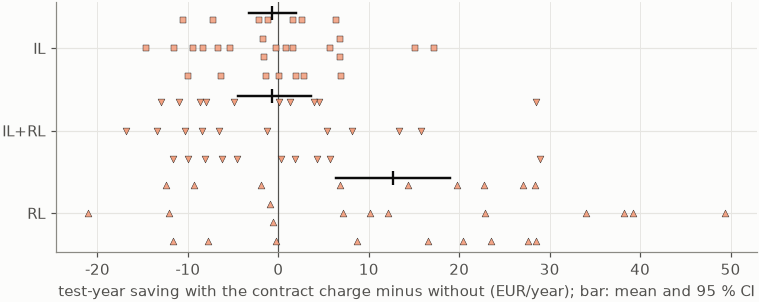

                                      contract method  n  mean  ci_lo  ci_hi  median  better      p  standing_line  p_holm
the study's (dynamic price, re-agreed monthly)     IL 30  -0.7   -3.3    2.0    -0.7      14 0.5699           -1.5  0.6569
the study's (dynamic price, re-agreed monthly)  IL+RL 30  -0.7   -4.4    3.6    -2.9      14 0.3285            2.7  0.6569
the study's (dynamic price, re-agreed monthly)     RL 30  12.6    6.4   19.0    13.2      20 0.0013           20.1  0.0040


In [5]:
# Paired, per household: the same learner paid for the contract minus the same
# learner paid for the settled bill only, on the TEST year of the same
# contract. Wilcoxon signed-rank via the study's own `paired_comparison`,
# Holm over the methods of one contract type.
GAIN_ROWS = []
for contract in [c for c in [STUDY] if "contract" in rc.arms_for(c)]:
    sub = RES[RES.contract == contract]
    wide = sub.pivot_table(index="ident", columns=["method", "arm"],
                           values="saving_total")
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
    stats = []
    for i, m in enumerate(METHODS):
        if (m, "contract") not in wide or (m, "excess") not in wide:
            continue
        pair = pd.DataFrame({"a": wide[(m, "contract")], "b": wide[(m, "excess")]}).dropna()
        d = (pair.a - pair.b).to_numpy()
        r = hs.paired_comparison(pair, "a", "b")
        lo, hi = fs.boot_ci(d, stat=np.mean)
        stats.append({"contract": TYPE_NAME[contract], "method": METHOD_NAME[m], "n": len(d),
                      "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                      "median": r["median_diff"], "better": r["n_a_greater"],
                      "p": r["p_value"],
                      "standing_line": float((sub[(sub.method == m) & (sub.arm == "contract")]
                                              .set_index("ident").saving_fixed
                                              - sub[(sub.method == m) & (sub.arm == "excess")]
                                              .set_index("ident").saving_fixed).mean())})
        col = fs.ctrl_color("SI", f"{m}_fc_h24")
        ax.scatter(d, i + fs.beeswarm(d), marker=fs.ctrl_marker(f"{m}_fc_h24"), s=20,
                   color=col, edgecolor=INK, lw=0.3, alpha=0.9, zorder=3)
        ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    for s_, p_h in zip(stats, fs.holm([s_["p"] for s_ in stats])):
        s_["p_holm"] = p_h
    GAIN_ROWS += stats
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([METHOD_NAME[m] for m in METHODS])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pf.PLAIN)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: what the contract charge "
                     f"adds to each learner",
           xlabel=f"test-year saving with the contract charge minus without ({UNIT}); "
                  f"bar: mean and 95 % CI", ylabel="")
    pf.show(fig, f"rlc_gain_{contract}")

GAIN = pd.DataFrame(GAIN_ROWS)
GAINS = pd.concat([globals().get('GAINS', pd.DataFrame()), GAIN], ignore_index=True)
with pd.option_context("display.width", 200):
    print(GAIN.round({"mean": 1, "ci_lo": 1, "ci_hi": 1, "median": 1,
                      "standing_line": 1, "p": 4, "p_holm": 4}).to_string(index=False))

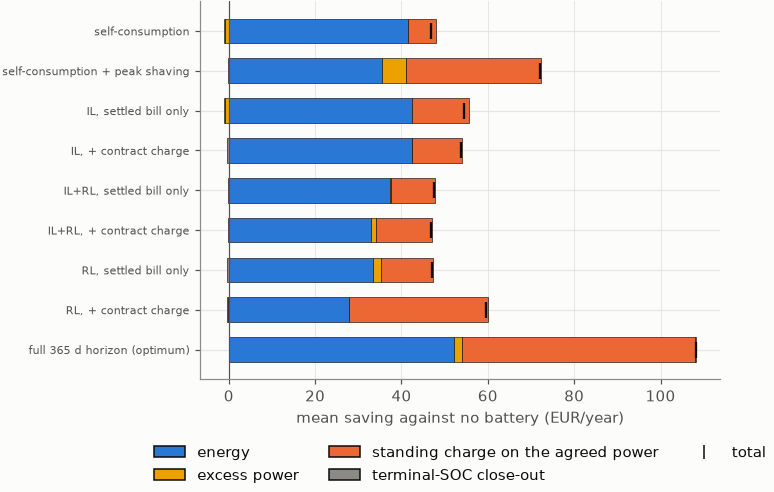

the study's (dynamic price, re-agreed monthly): mean saving by line, EUR/year
                                 energy  power  standing  closeout  total    efc
self-consumption                   41.6   -0.8       6.3      -0.3   46.8   72.4
self-consumption + peak shaving    35.5    5.4      31.3      -0.1   72.2   74.7
IL, settled bill only              42.5   -0.8      13.1      -0.3   54.5   92.7
IL, + contract charge              42.4    0.0      11.6      -0.3   53.7   95.2
IL+RL, settled bill only           37.2    0.2      10.3      -0.3   47.5  101.5
IL+RL, + contract charge           33.0    1.0      13.0      -0.2   46.8  116.0
RL, settled bill only              33.3    2.0      12.1      -0.3   47.0  131.5
RL, + contract charge              27.9   -0.2      32.2      -0.2   59.7  145.6
full 365 d horizon (optimum)       52.2    1.9      54.0       0.2  108.3  157.1 



In [6]:
# Where each controller's saving comes from, by bill line. The standing-charge
# line is the one the contract charge was written to move.
LINES_ORDER = ["energy", "power", "standing", "closeout"]
for contract in [c for c in [STUDY] if "contract" in rc.arms_for(c)]:
    best_rule = (SUMMARY[contract].drop(index=[c for c in SUMMARY[contract].index
                                               if ":" in c or c in ("milp_full", "price_oracle")])
                 ["mean"].idxmax())
    rows = (["self_consumption", best_rule]
            + [f"{m}:{a}" for m in METHODS for a in ("excess", "contract")]
            + ["milp_full"])
    rows = list(dict.fromkeys(r for r in rows if r in SUMMARY[contract].index))
    means = (RANK[(RANK.contract == contract)].groupby("controller")[LINES_ORDER]
             .mean().reindex(rows))
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.05 * len(rows)))
    y = np.arange(len(rows))
    pos = np.zeros(len(rows))
    neg = np.zeros(len(rows))
    for name in LINES_ORDER:
        v = means[name].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.barh(y, v, left=base, color=LINE_COLOR[name], edgecolor=INK, lw=0.4,
                height=0.62)
        pos += np.clip(v, 0, None)
        neg += np.clip(v, None, 0)
    tot = means.sum(axis=1).to_numpy()
    ax.scatter(tot, y, marker="|", s=120, color=INK, zorder=4)
    ax.set_yticks(y)
    ax.set_yticklabels([label(c) for c in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Patch(facecolor=LINE_COLOR[n], edgecolor=INK, label=LINE_NAME[n])
                       for n in LINES_ORDER]
                  + [Line2D([], [], marker="|", ls="", color=INK, markersize=9,
                            label="total")], where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving by bill line",
           xlabel=f"mean saving against no battery ({UNIT})", ylabel="")
    pf.show(fig, f"rlc_lines_{contract}")
    print(f"{TYPE_NAME[contract]}: mean saving by line, {UNIT}")
    out = means.assign(total=tot,
                       efc=RANK[RANK.contract == contract].groupby("controller")["efc"]
                       .mean().reindex(rows))
    out.index = [label(c).replace("\n", " ") for c in out.index]
    print(out.round(1).to_string(), "\n")

## 4. The price lists

The two price lists the study did not run, each with the study's agreed-power rule: the
**active** list (GEN-I *Aktivni cenik samooskrbe*: solar low season 4.1, solar high season
11.5, base 13.0, peak 19.3 c/kWh for energy, and a matching four-price buy-back) and the
**single-tariff** list (GEN-I *Redni cenik* for self-supply: 10.3 c/kWh for energy in, 5.4
out). Every
controller was trained and scored under the list it is shown on: its own teacher MILP, its
own reward (`SIActivePriceReward`, `SISingleTariffReward` — the bill of that list plus the
contract charge), its own rules and optimum as references. Same three figures as section 3,
per list.

**Active list — the learned controllers win.** All six learned rows sit at 273–277 EUR/a,
**60 EUR/a above the best rule** (`price threshold`, 214; 29–30 of 30 households ahead,
p < 0.0001) and at 83–84 % of the whole-year optimum (330). This is the first SI contract in
the study on which a learned controller beats every rule, and it does so by a margin larger
than anything the dynamic list offers in total. The reason is on the bill: a 15-cent spread
that repeats every working day is exactly what a learner picks up from two years of data,
and a threshold rule tuned for an hourly market price is not built for four posted ones.
The contract charge adds nothing to the total here (+0.5 to +2.8, none significant) — but
it is not ignored: the DQN paid for it takes 23 EUR/a off the standing charge instead of 1,
and gives the same 18 back on energy. With 278 EUR/a of energy on the table, a kW of
contract is simply worth less than the cycles it costs.

**Single-tariff list — the contract is all there is, and the rule still wins.** Nothing can
be arbitraged, so the bill moves only through self-consumption and the contract. RL with
the contract charge is the best learned controller (78.0; +6.3 EUR/a over RL without it,
p_holm 0.02; +6.7 over plain self-consumption, 21 of 30) and is 13.4 behind
`self-consumption + peak shaving` (91.4). The clone is *below* self-consumption here (64.8
against 71.3): it copies a teacher whose grid charging only pays with foresight of the
household's peaks, and on a list with no price signal there is nothing else to copy.

Two caveats for these two lists. The rules are the study's, with the parameters tuned for
the dynamic list (`RULE_PARAMS`); a rule re-tuned for four posted prices would narrow the
60 EUR/a, though the clock rule that *is* built for posted prices (`tariff arbitrage`)
is at 172. And the price lists are 2025–26 lists applied to the 2012–13 test year, exactly
as the dynamic list is.

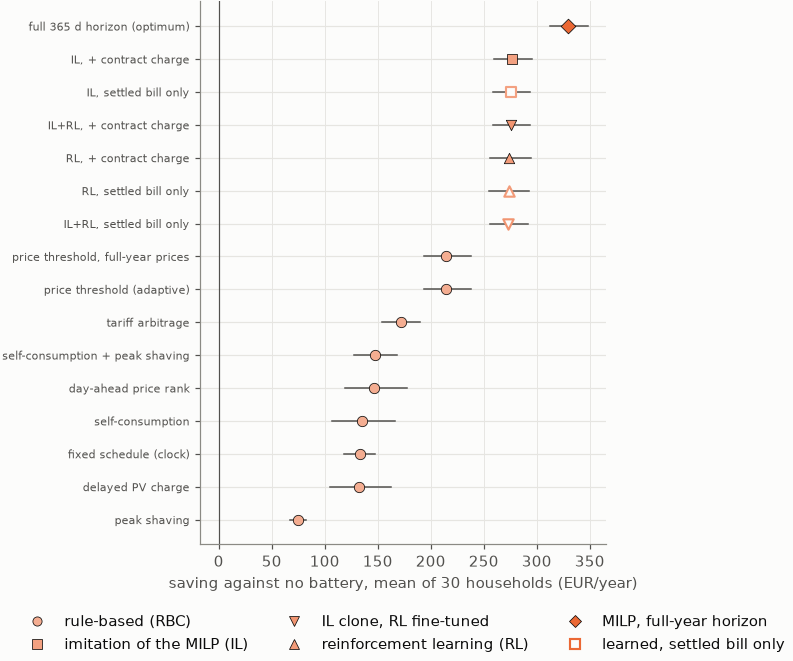

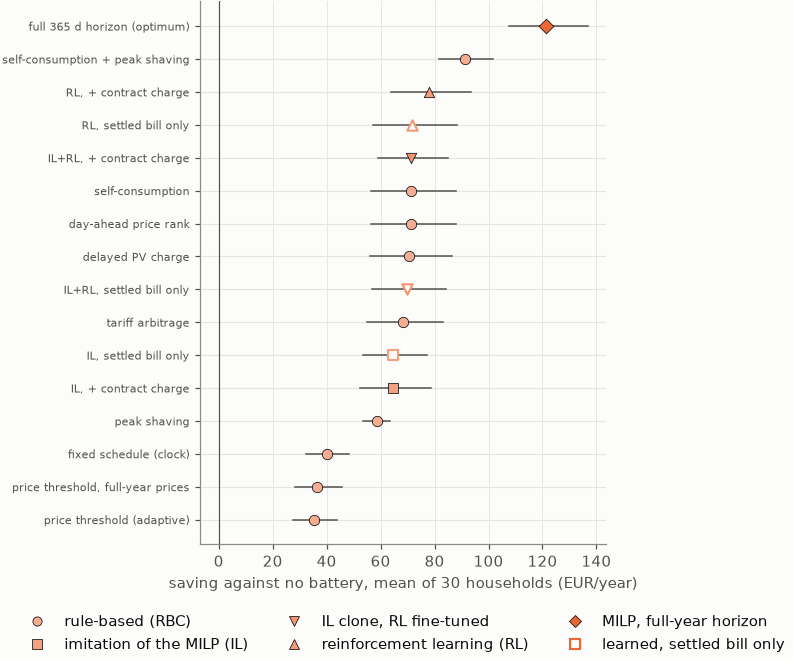


active (4-tariff) price -- saving on the total bill, EUR/year
                                    mean  ci_lo  ci_hi  median
full 365 d horizon (optimum)       329.8  312.9  348.0   328.9
IL, + contract charge              276.9  259.8  295.5   271.2
IL, settled bill only              275.8  259.2  293.9   276.8
IL+RL, + contract charge           275.8  258.8  294.0   271.0
RL, + contract charge              274.0  255.6  294.3   262.2
RL, settled bill only              273.6  255.4  293.1   267.0
IL+RL, settled bill only           272.9  255.7  291.5   269.0
price threshold, full-year prices  214.5  194.0  238.2   195.0
price threshold (adaptive)         214.2  193.6  238.0   194.8
tariff arbitrage                   172.0  154.0  190.1   171.7
self-consumption + peak shaving    147.5  127.9  167.9   132.8
day-ahead price rank               146.9  119.2  177.7   124.6
self-consumption                   135.0  106.5  166.7   116.6
fixed schedule (clock)             132.9  118.0  147.6 

In [7]:
# One figure per contract type: every controller's saving on the TOTAL bill
# (the closed bill plus the standing charge of the contract it ends up on),
# against that contract's own no-battery row. Mean and bootstrap 95 % CI over
# the households; the specialist reward's rows are filled, the other hollow.
for contract in [c for c in FAMILIES["price"] if c != STUDY]:
    sub = RANK[(RANK.contract == contract) & (RANK.controller != "no_battery")]
    wide = sub.pivot(index="ident", columns="controller", values="total").dropna(axis=1)
    order = wide.mean().sort_values().index.tolist()
    rows = []
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.042 * len(order)))
    for i, c in enumerate(order):
        v = wide[c].to_numpy()
        lo, hi = fs.boot_ci(v, stat=np.mean)
        learned = ":" in c
        special = learned and c.endswith(":" + rc.SPECIALIST[contract])
        col = fs.ctrl_color("SI", family_key(c))
        ax.plot([lo, hi], [i, i], color=INK_2, lw=1.0, zorder=2)
        ax.scatter([v.mean()], [i], marker=fs.ctrl_marker(family_key(c)), s=46,
                   facecolor=(SURFACE if learned and not special else col),
                   edgecolor=(col if learned and not special else INK),
                   lw=(1.4 if learned and not special else 0.5), zorder=3)
        rows.append({"controller": c, "mean": v.mean(), "ci_lo": lo, "ci_hi": hi,
                     "median": float(np.median(v))})
    SUMMARY[contract] = pd.DataFrame(rows).set_index("controller")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([label(c) for c in order], fontsize=7.5)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    fams = [f for f in ("RBC", "IL", "IL+RL", "RL", "MILP")]
    handles = [Line2D([], [], marker=fs.FAMILY_MARKER[f], ls="",
                      color=pf.mix(fs.TARIFF_COLOR["SI"], "#ffffff", fs.FAMILY_SHADE[f]),
                      markeredgecolor=INK, markeredgewidth=0.5,
                      label=fs.FAMILY_LABEL[f]) for f in fams]
    if any(":excess" in c for c in order) and any(":contract" in c for c in order):
        handles.append(Line2D([], [], marker="s", ls="", markerfacecolor=SURFACE,
                              markeredgecolor=fs.TARIFF_COLOR["SI"], markeredgewidth=1.4,
                              label="learned, " + ARM_NAME["excess"]))
    pf.key_legend(ax, handles, where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving on the total bill",
           xlabel=f"saving against no battery, mean of {wide.shape[0]} households ({UNIT})",
           ylabel="")
    pf.show(fig, f"rlc_ranking_{contract}")

for contract in [c for c in FAMILIES["price"] if c != STUDY]:
    print(f"\n{TYPE_NAME[contract]} -- saving on the total bill, {UNIT}")
    t = SUMMARY[contract].sort_values("mean", ascending=False)
    t.index = [label(c).replace("\n", " ") for c in t.index]
    print(t.round(1).to_string())

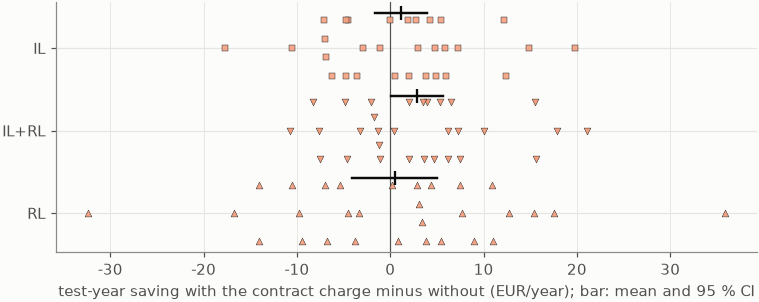

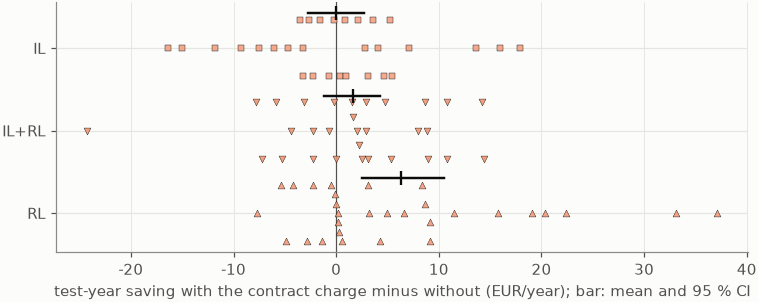

               contract method  n  mean  ci_lo  ci_hi  median  better      p  standing_line  p_holm
active (4-tariff) price     IL 30   1.1   -1.6    4.0     1.9      17 0.5425           -1.7  1.0000
active (4-tariff) price  IL+RL 30   2.8    0.1    5.7     2.8      18 0.1094            2.6  0.3283
active (4-tariff) price     RL 30   0.5   -4.1    5.0     1.9      17 0.8553           21.9  1.0000
    single-tariff price     IL 30  -0.0   -2.8    2.7     0.1      15 1.0000           -1.5  1.0000
    single-tariff price  IL+RL 30   1.7   -1.2    4.2     2.1      18 0.1347            3.0  0.2695
    single-tariff price     RL 30   6.3    2.6   10.5     3.2      20 0.0054           16.4  0.0161


In [8]:
# Paired, per household: the same learner paid for the contract minus the same
# learner paid for the settled bill only, on the TEST year of the same
# contract. Wilcoxon signed-rank via the study's own `paired_comparison`,
# Holm over the methods of one contract type.
GAIN_ROWS = []
for contract in [c for c in [c for c in FAMILIES["price"] if c != STUDY] if "contract" in rc.arms_for(c)]:
    sub = RES[RES.contract == contract]
    wide = sub.pivot_table(index="ident", columns=["method", "arm"],
                           values="saving_total")
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
    stats = []
    for i, m in enumerate(METHODS):
        if (m, "contract") not in wide or (m, "excess") not in wide:
            continue
        pair = pd.DataFrame({"a": wide[(m, "contract")], "b": wide[(m, "excess")]}).dropna()
        d = (pair.a - pair.b).to_numpy()
        r = hs.paired_comparison(pair, "a", "b")
        lo, hi = fs.boot_ci(d, stat=np.mean)
        stats.append({"contract": TYPE_NAME[contract], "method": METHOD_NAME[m], "n": len(d),
                      "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                      "median": r["median_diff"], "better": r["n_a_greater"],
                      "p": r["p_value"],
                      "standing_line": float((sub[(sub.method == m) & (sub.arm == "contract")]
                                              .set_index("ident").saving_fixed
                                              - sub[(sub.method == m) & (sub.arm == "excess")]
                                              .set_index("ident").saving_fixed).mean())})
        col = fs.ctrl_color("SI", f"{m}_fc_h24")
        ax.scatter(d, i + fs.beeswarm(d), marker=fs.ctrl_marker(f"{m}_fc_h24"), s=20,
                   color=col, edgecolor=INK, lw=0.3, alpha=0.9, zorder=3)
        ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    for s_, p_h in zip(stats, fs.holm([s_["p"] for s_ in stats])):
        s_["p_holm"] = p_h
    GAIN_ROWS += stats
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([METHOD_NAME[m] for m in METHODS])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pf.PLAIN)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: what the contract charge "
                     f"adds to each learner",
           xlabel=f"test-year saving with the contract charge minus without ({UNIT}); "
                  f"bar: mean and 95 % CI", ylabel="")
    pf.show(fig, f"rlc_gain_{contract}")

GAIN = pd.DataFrame(GAIN_ROWS)
GAINS = pd.concat([globals().get('GAINS', pd.DataFrame()), GAIN], ignore_index=True)
with pd.option_context("display.width", 200):
    print(GAIN.round({"mean": 1, "ci_lo": 1, "ci_hi": 1, "median": 1,
                      "standing_line": 1, "p": 4, "p_holm": 4}).to_string(index=False))

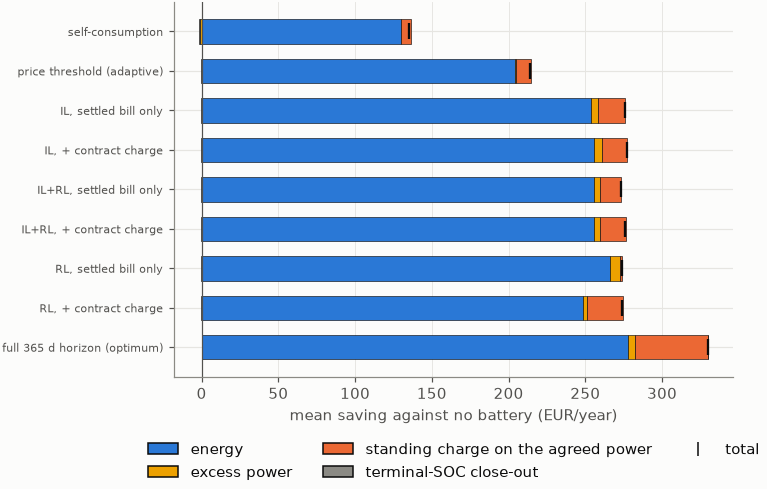

active (4-tariff) price: mean saving by line, EUR/year
                              energy  power  standing  closeout  total    efc
self-consumption               130.2   -0.8       6.3      -0.7  135.0   72.4
price threshold (adaptive)     204.1    0.5      10.3      -0.6  214.2  139.0
IL, settled bill only          253.9    4.0      18.2      -0.3  275.8  191.5
IL, + contract charge          255.9    4.8      16.5      -0.2  276.9  192.8
IL+RL, settled bill only       255.3    4.1      14.0      -0.5  272.9  193.3
IL+RL, + contract charge       255.8    3.9      16.6      -0.6  275.8  195.2
RL, settled bill only          266.2    6.7       1.3      -0.6  273.6  207.8
RL, + contract charge          248.2    3.2      23.2      -0.6  274.0  207.2
full 365 d horizon (optimum)   278.0    4.4      47.4       0.0  329.8  212.2 



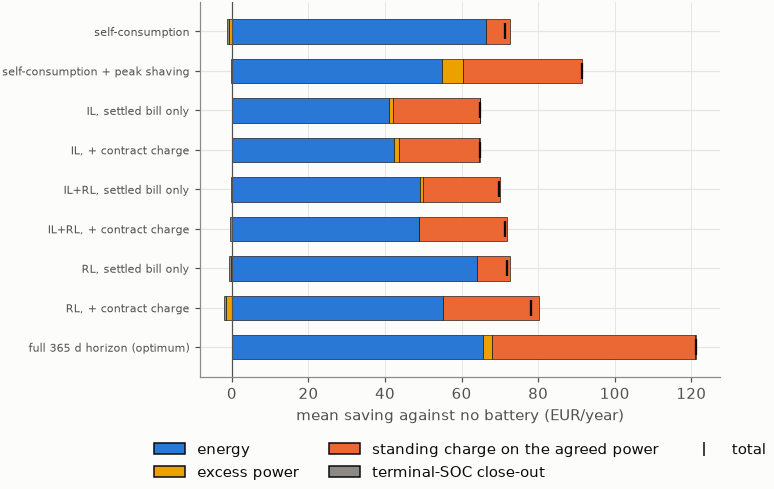

single-tariff price: mean saving by line, EUR/year
                                 energy  power  standing  closeout  total    efc
self-consumption                   66.4   -0.8       6.3      -0.6   71.3   72.4
self-consumption + peak shaving    54.9    5.4      31.3      -0.1   91.4   74.7
IL, settled bill only              40.9    1.2      22.6       0.1   64.8   45.1
IL, + contract charge              42.3    1.3      21.1       0.1   64.8   46.8
IL+RL, settled bill only           49.1    0.9      19.9      -0.3   69.7   54.7
IL+RL, + contract charge           48.9    0.0      22.9      -0.5   71.4   56.7
RL, settled bill only              63.9   -0.3       8.6      -0.5   71.7   74.4
RL, + contract charge              55.1   -1.6      25.0      -0.5   78.0  104.2
full 365 d horizon (optimum)       65.5    2.5      52.8       0.4  121.3   77.0 



In [9]:
# Where each controller's saving comes from, by bill line. The standing-charge
# line is the one the contract charge was written to move.
LINES_ORDER = ["energy", "power", "standing", "closeout"]
for contract in [c for c in [c for c in FAMILIES["price"] if c != STUDY] if "contract" in rc.arms_for(c)]:
    best_rule = (SUMMARY[contract].drop(index=[c for c in SUMMARY[contract].index
                                               if ":" in c or c in ("milp_full", "price_oracle")])
                 ["mean"].idxmax())
    rows = (["self_consumption", best_rule]
            + [f"{m}:{a}" for m in METHODS for a in ("excess", "contract")]
            + ["milp_full"])
    rows = list(dict.fromkeys(r for r in rows if r in SUMMARY[contract].index))
    means = (RANK[(RANK.contract == contract)].groupby("controller")[LINES_ORDER]
             .mean().reindex(rows))
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.05 * len(rows)))
    y = np.arange(len(rows))
    pos = np.zeros(len(rows))
    neg = np.zeros(len(rows))
    for name in LINES_ORDER:
        v = means[name].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.barh(y, v, left=base, color=LINE_COLOR[name], edgecolor=INK, lw=0.4,
                height=0.62)
        pos += np.clip(v, 0, None)
        neg += np.clip(v, None, 0)
    tot = means.sum(axis=1).to_numpy()
    ax.scatter(tot, y, marker="|", s=120, color=INK, zorder=4)
    ax.set_yticks(y)
    ax.set_yticklabels([label(c) for c in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Patch(facecolor=LINE_COLOR[n], edgecolor=INK, label=LINE_NAME[n])
                       for n in LINES_ORDER]
                  + [Line2D([], [], marker="|", ls="", color=INK, markersize=9,
                            label="total")], where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving by bill line",
           xlabel=f"mean saving against no battery ({UNIT})", ylabel="")
    pf.show(fig, f"rlc_lines_{contract}")
    print(f"{TYPE_NAME[contract]}: mean saving by line, {UNIT}")
    out = means.assign(total=tot,
                       efc=RANK[RANK.contract == contract].groupby("controller")["efc"]
                       .mean().reindex(rows))
    out.index = [label(c).replace("\n", " ") for c in out.index]
    print(out.round(1).to_string(), "\n")

### Do separately trained models help — across price lists?

Every model was scored on the test year of every price list. A model is the price list it
was trained on plus the reward it was trained with — six per learner. The marked bar in each
group is the list's *own* model.

**Yes, and by a wide margin.** Unlike the agreed-power rules of section 5, the own model is
the tallest bar, or level with its own settled-bill twin, in eight groups of nine (the
exception: the clone on the single-tariff list, where the active-list clone is level with
it):

- **On the active list** the own models save 273–277 EUR/a; a model trained on the dynamic
  list saves 97–171 and one trained on the single-tariff list 84–202. For the clone the loss
  from using the dynamic-list model is **111 EUR/a, on 30 of 30 households**.
- **On the dynamic list** the own clone saves 54; the active-list clone 33–34 (−20,
  24–26 of 30); a single-tariff model 2–4. The same for RL: 59.7 against 29–38 and 16–21.
- **On the single-tariff list** a dynamic-list model is the worst choice (−0.6 to 34);
  an active-list model comes close to the own one for the clone (59–67 against 65) but not
  for RL (54–65 against 78).

As a policy for a household that could be on any of the three: **one model per price list
saves 131–137 EUR/a averaged over the lists; the best single model — the active-list one —
113–126**, and the panel's own dynamic-list models 50–86. (The average is dominated by the
active list, where the money is; the per-list losses above are the cleaner statement.)

Why it is so different from the agreed-power rules: a price list changes *when it pays to
move energy*, which is the policy itself, and a model has only ever seen one answer to that.
An agreed-power rule changes how much a shaved peak is worth, which a model trained on any
contract that pays for peaks has already learned to act on.

One thing was done so that this is a statement about policies and not about arithmetic: on
the single-tariff and active lists the price features are scaled by at least one cent
(`PRICE_SCALE`). A price that is one number in training would otherwise be divided by a
spread of nearly zero, and a single-tariff model shown a moving price would fail for that
reason alone.

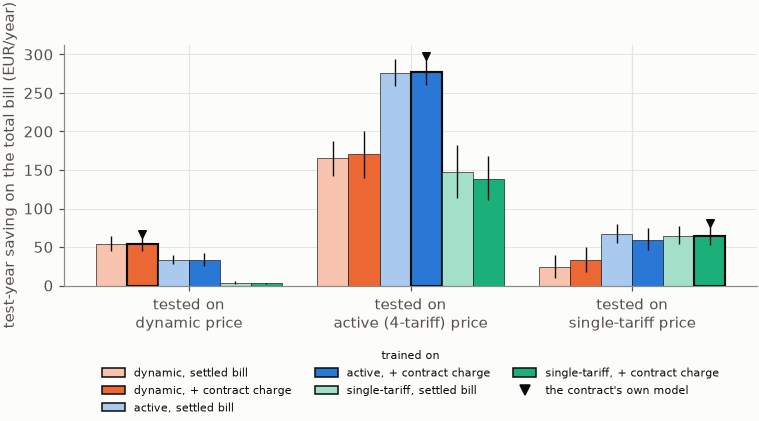

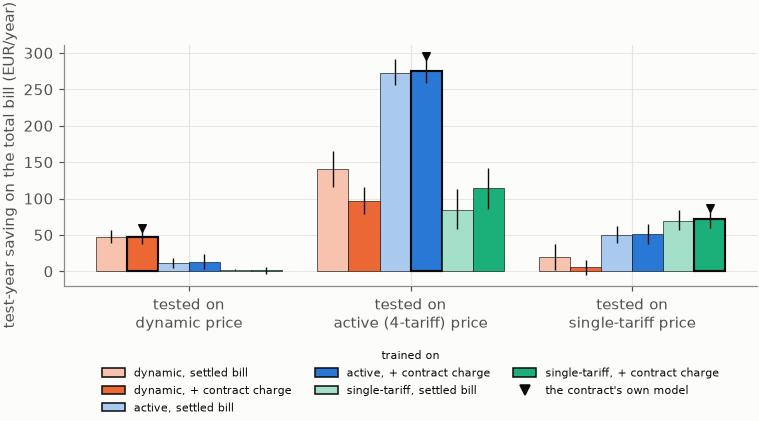

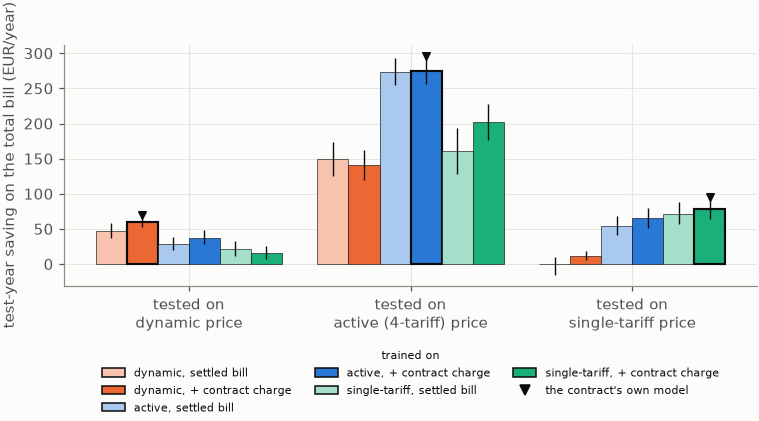


IL: mean test-year saving on the total bill, EUR/year (rows: trained on; columns: tested on)
tested_on                                   monthly  active  single
dynamic price, settled bill only               54.5   165.9    24.6
dynamic price, + contract charge               53.7   170.7    33.5
active (4-tariff) price, settled bill only     33.7   275.8    67.0
active (4-tariff) price, + contract charge     33.2   276.9    59.1
single-tariff price, settled bill only          3.8   147.4    64.8
single-tariff price, + contract charge          2.7   138.8    64.8

IL+RL: mean test-year saving on the total bill, EUR/year (rows: trained on; columns: tested on)
tested_on                                   monthly  active  single
dynamic price, settled bill only               47.5   140.3    20.0
dynamic price, + contract charge               46.8    96.8     6.2
active (4-tariff) price, settled bill only     11.3   272.9    49.7
active (4-tariff) price, + contract charge     13.2   275.8  

In [10]:
# Every model on every contract type's TEST year. A model is (the contract it
# was trained on, the reward it was trained with); a group of bars is one test
# contract. The marked bar is the contract's OWN model: trained on that
# contract with the reward that is its bill (`rc.SPECIALIST`).
FAM = "price"
TYPES = FAMILIES[FAM]
MODELS = [(t, a) for t in TYPES for a in rc.arms_for(t)]


def model_name(trained, arm):
    return f"{LABEL[FAM][trained]}, {ARM_NAME[arm]}"


def model_color(trained, arm):
    return CONTRACT_COLOR[trained] if arm == rc.SPECIALIST[trained] or trained == "fixed" \
        else pf.mix(CONTRACT_COLOR[trained], "#ffffff", 0.6)


if CROSS.empty or not set(TYPES) <= set(CROSS.tested_on) & set(CROSS.trained_on):
    print("cross-evaluation incomplete for this family: "
          "`python3 run_rl_contract.py cross --jobs 12`")
else:
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                    & CROSS.tested_on.isin(TYPES)]
        fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.5))
        x = np.arange(len(TYPES))
        w = 0.84 / len(MODELS)
        for k, (trained, arm) in enumerate(MODELS):
            xs = x + (k - (len(MODELS) - 1) / 2) * w
            for j, tested in enumerate(TYPES):
                v = sub[(sub.trained_on == trained) & (sub.arm == arm)
                        & (sub.tested_on == tested)].saving_total.to_numpy()
                if not len(v):
                    continue
                lo, hi = fs.boot_ci(v, stat=np.mean)
                own = trained == tested and arm == rc.SPECIALIST[tested]
                ax.bar(xs[j], v.mean(), width=w, color=model_color(trained, arm),
                       edgecolor=INK, lw=(1.4 if own else 0.4), zorder=2)
                ax.vlines(xs[j], lo, hi, color=INK, lw=0.9, zorder=3)
                if own:
                    ax.scatter([xs[j]], [hi + 2.5], marker="v", s=24, color=INK, zorder=4)
        ax.set_xticks(x)
        ax.set_xticklabels([f"tested on\n{LABEL[FAM][c]}" for c in TYPES])
        ax.yaxis.set_major_formatter(EUR)
        ax.grid(axis="y", color=pf.GRID, lw=0.6)
        ax.set_axisbelow(True)
        pf.key_legend(ax, [Patch(facecolor=model_color(t, a), edgecolor=INK,
                                 label=f"{SHORT[FAM][t]}, {ARM_SHORT[a]}")
                           for t, a in MODELS]
                      + [Line2D([], [], marker="v", ls="", color=INK,
                                label="the contract's own model")],
                      where="below", below_in=0.62, ncol=3, title="trained on",
                      fontsize=7.5, title_fontsize=7.5)
        finish(ax, title=f"SI {METHOD_NAME[m]}: every model on every {FAMILY_NAME[FAM]}",
               xlabel="", ylabel=f"test-year saving on the total bill ({UNIT})")
        pf.show(fig, f"rlc_cross_{FAM}_{m}")

    # The matrices behind the bars.
    for m in METHODS:
        mat = (CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                     & CROSS.tested_on.isin(TYPES)]
               .pivot_table(index=["trained_on", "arm"], columns="tested_on",
                            values="saving_total").reindex(MODELS).reindex(columns=list(TYPES)))
        mat.index = [model_name(t, a) for t, a in mat.index]
        print(f"\n{METHOD_NAME[m]}: mean test-year saving on the total bill, {UNIT} "
              f"(rows: trained on; columns: tested on)")
        print(mat.round(1).to_string())

    # The question as a paired test: on each contract's test year, the
    # contract's own model minus every other model, household by household.
    XROWS = []
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)]
        for tested in TYPES:
            own = sub[(sub.tested_on == tested) & (sub.trained_on == tested)
                      & (sub.arm == rc.SPECIALIST[tested])].set_index("ident").saving_total
            for trained, arm in MODELS:
                if trained == tested and arm == rc.SPECIALIST[tested]:
                    continue
                other = sub[(sub.tested_on == tested) & (sub.trained_on == trained)
                            & (sub.arm == arm)].set_index("ident").saving_total
                pair = pd.DataFrame({"own": own, "other": other}).dropna()
                if pair.empty:
                    continue
                r = hs.paired_comparison(pair, "own", "other")
                d = (pair.own - pair.other).to_numpy()
                lo, hi = fs.boot_ci(d, stat=np.mean)
                XROWS.append({"method": METHOD_NAME[m],
                              "tested_on": LABEL[FAM][tested],
                              "instead_of": model_name(trained, arm), "n": len(d),
                              "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                              "own_better": r["n_a_greater"], "p": r["p_value"]})
    XT = pd.DataFrame(XROWS)
    XTS = dict(globals().get('XTS', {}), **{FAM: XT})
    XT["p_holm"] = np.nan
    for m in XT.method.unique():
        sel = XT.method == m
        XT.loc[sel, "p_holm"] = fs.holm(XT.loc[sel, "p"].tolist())
    with pd.option_context("display.width", 220, "display.max_rows", 100):
        print(f"\nthe contract's own model minus another model ({UNIT}; "
              f"positive = the own model saves more; Holm within a method):")
        print(XT.round({"mean": 1, "ci_lo": 1, "ci_hi": 1, "p": 4, "p_holm": 4})
              .to_string(index=False))

mean over households and the three price lists, EUR/year:
method                                                    IL  IL+RL     RL
policy                                                                    
a model per price list                                 131.8  131.3  137.2
one model: dynamic price, settled bill only             81.7   69.3   65.5
one model: dynamic price, + contract charge             86.0   49.9   70.8
one model: active (4-tariff) price, settled bill only  125.5  111.3  118.9
one model: active (4-tariff) price, + contract charge  123.1  113.2  125.6
one model: single-tariff price, settled bill only       72.0   52.0   84.5
one model: single-tariff price, + contract charge       68.7   62.4   98.7


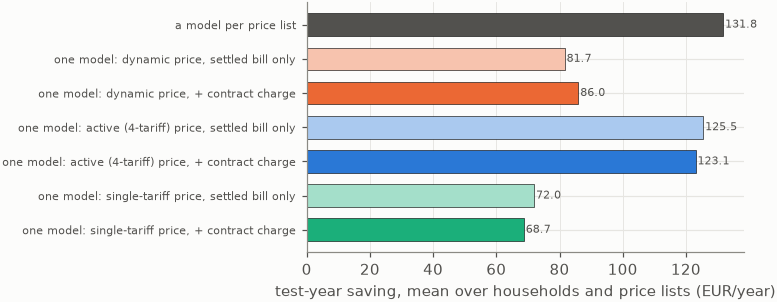

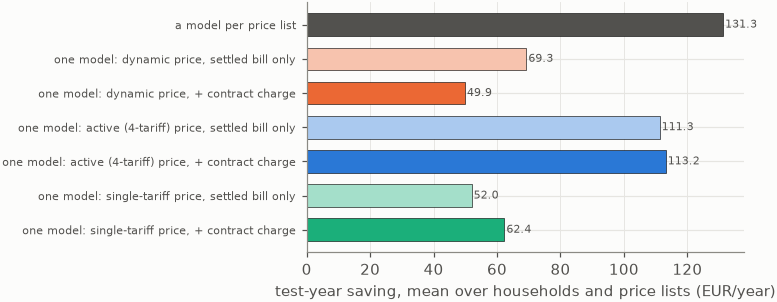

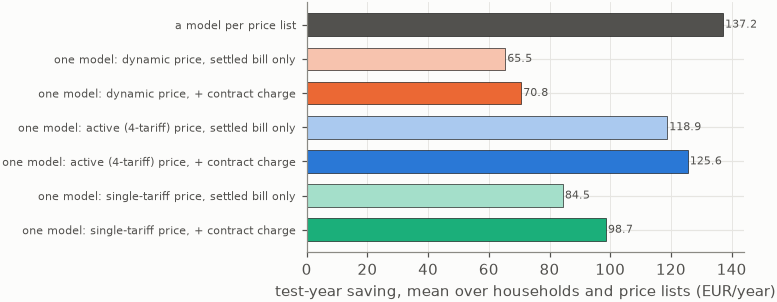

In [11]:
# Three ways to equip a household that could be on any of the three contracts:
#   per contract   each contract's own model (its own reward, trained on it)
#   by reward      (agreed-power rules only) TWO models, split by whether the
#                  dispatch moves the contract: the monthly contract-charge
#                  model wherever it does, the signed contract's own model
#                  where it does not
#   one model      a single model everywhere (every candidate is shown)
FAM = "price"
TYPES = FAMILIES[FAM]
MODELS = [(t, a) for t in TYPES for a in rc.arms_for(t)]
if not CROSS.empty and set(TYPES) <= set(CROSS.tested_on) & set(CROSS.trained_on):
    rows = []
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                    & CROSS.tested_on.isin(TYPES)]
        cell = sub.pivot_table(index=["trained_on", "arm"], columns="tested_on",
                               values="saving_total")
        per = np.mean([cell.loc[(c, rc.SPECIALIST[c]), c] for c in TYPES])
        rows.append({"method": METHOD_NAME[m],
                     "policy": f"a model per {FAMILY_NAME[FAM]}",
                     "saving": per, "kind": "per"})
        if FAM == "power":
            two = np.mean([cell.loc[("fixed", "excess"), "fixed"]]
                          + [cell.loc[("monthly", "contract"), c]
                             for c in ("monthly", "annual")])
            rows.append({"method": METHOD_NAME[m], "policy": "two models, by reward",
                         "saving": two, "kind": "two"})
        for t, a in MODELS:
            rows.append({"method": METHOD_NAME[m], "policy": "one model: " + model_name(t, a),
                         "saving": cell.loc[(t, a), list(TYPES)].mean(),
                         "kind": "one", "model": (t, a)})
    POLICY = pd.DataFrame(rows)
    POLICIES = dict(globals().get("POLICIES", {}), **{FAM: POLICY})
    print(f"mean over households and the three {FAMILY_NAME[FAM]}s, {UNIT}:")
    print(POLICY.pivot(index="policy", columns="method", values="saving")
          .reindex(POLICY.policy.drop_duplicates())[[METHOD_NAME[m] for m in METHODS]]
          .round(1).to_string())

    for m in METHODS:
        d = POLICY[POLICY.method == METHOD_NAME[m]].reset_index(drop=True)
        fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
        y = np.arange(len(d))
        cols = [INK_2 if k == "per" else MUTED if k == "two" else model_color(*mod)
                for k, mod in zip(d.kind, d.get("model", [None] * len(d)))]
        ax.barh(y, d.saving, color=cols, edgecolor=INK, lw=0.4, height=0.66)
        for yi, v in zip(y, d.saving):
            ax.text(v + 0.6, yi, f"{v:.1f}", va="center", fontsize=7.5, color=INK_2)
        ax.set_yticks(y)
        ax.set_yticklabels(d.policy, fontsize=7.5)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(EUR)
        ax.grid(axis="x", color=pf.GRID, lw=0.6)
        ax.set_axisbelow(True)
        finish(ax, title=f"SI {METHOD_NAME[m]}: how many models, across {FAMILY_NAME[FAM]}s",
               xlabel=f"test-year saving, mean over households and {FAMILY_NAME[FAM]}s ({UNIT})",
               ylabel="")
        pf.show(fig, f"rlc_separate_models_{FAM}_{m}")

## 5. The agreed-power rules

The other family: the study's price list throughout, and the agreed power either a **signed**
number (the operator's figure — the mean of the five highest no-battery draws per block over
the metering year before), or the study's statistic over a **rolling 12 months** instead of
one. Ranking, contract-charge gain and bill lines per rule, then the cross-evaluation.

- **Rolling 12 months.** RL with the contract charge leads the learned controllers (53.4;
  +9.7 EUR/a over RL without it, 21 of 30, p_holm 0.04), then the clone trained on the
  settled bill (51.5). The clone trained *with* the contract features is worse (43.5; −8.0,
  p_holm 0.02).
- **Signed.** Nothing beats plain self-consumption (41.4): the clone ties it (40.5), the two
  reinforcement learners lose 4–5 EUR/a to it. With the standing charge fixed and the
  dynamic list's energy prices nearly flat, self-consumption is close to all there is; the
  optimum's own lead is 14.5.

**Separately trained models do not help here.** The own model is the tallest bar in one
group of nine (RL on the study's contract):

- **RL.** The monthly contract-charge model is the best model on the monthly contract (59.7)
  *and* on the 12-month one (59.3 against 53.4 for that contract's own model; not
  significant after Holm). On the signed contract it is the worst (27.3): the signed
  contract's own model beats it by 9.3 EUR/a (p_holm 0.001) — but so does every other model
  trained on a settled bill, on any contract (36–39).
- **IL.** The panel's clone is the best clone on all three, including the two it was not
  trained on: +4.0 EUR/a over the signed contract's own (p_holm 0.01), +10.5 over the
  12-month contract's own (p_holm 0.0002).

| mean over the three rules, EUR/a | IL | IL+RL | RL |
|---|---|---|---|
| a model per agreed-power rule | 45.9 | 41.9 | 49.9 |
| two models, split by whether the dispatch moves the contract | 48.3 | 41.6 | **51.8** |
| the best single model | **51.0** (the panel's) | **42.5** (the panel's) | 48.8 (monthly, contract charge) |

What RL needs across agreed-power rules is the right *reward family* — contract charge where
the contract follows the dispatch, settled bill where it does not — and one model of each.
(The "best single model" row is picked on the test year among five, so it is a description;
the row that matters is that the per-rule policy is beaten without any picking.)

Two feature fixes are part of these results: on a signed contract the agreed power is one
number in training and another in the test year, and it had to be taken out of the inputs
(the first run had clones that never moved the battery); on the 12-month contract its scale
is floored (`run_rl_contract.AGREED_KW_SCALE`).

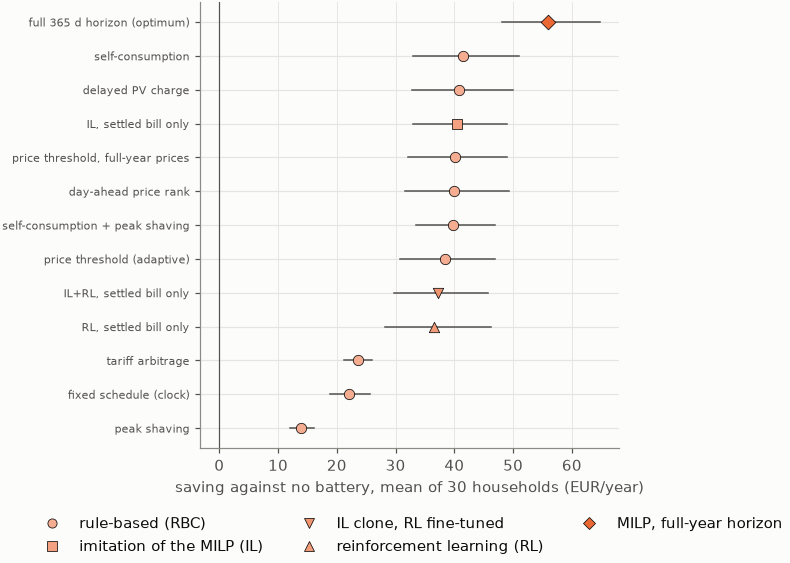

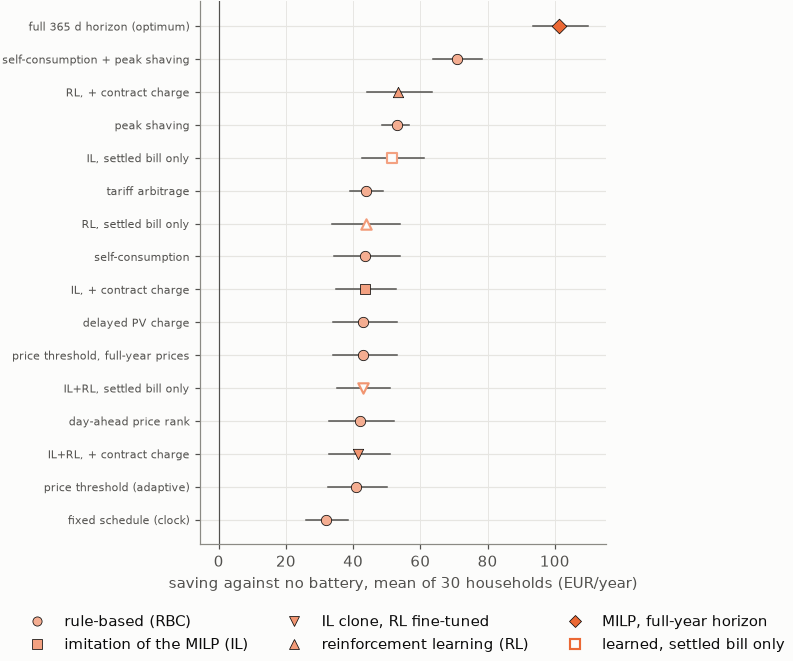


signed (fixed) -- saving on the total bill, EUR/year
                                   mean  ci_lo  ci_hi  median
full 365 d horizon (optimum)       55.9   48.1   64.7    51.2
self-consumption                   41.4   33.0   50.9    36.5
delayed PV charge                  40.9   32.8   49.9    36.4
IL, settled bill only              40.5   33.0   48.9    36.6
price threshold, full-year prices  40.1   32.2   49.0    35.3
day-ahead price rank               39.9   31.6   49.3    34.3
self-consumption + peak shaving    39.8   33.5   46.9    38.0
price threshold (adaptive)         38.4   30.8   46.9    33.8
IL+RL, settled bill only           37.2   29.7   45.8    31.3
RL, settled bill only              36.6   28.2   46.2    31.8
tariff arbitrage                   23.6   21.3   26.0    23.9
fixed schedule (clock)             22.1   18.8   25.7    21.1
peak shaving                       13.9   12.0   16.1    12.4

rolling 12 months -- saving on the total bill, EUR/year
                     

In [12]:
# One figure per contract type: every controller's saving on the TOTAL bill
# (the closed bill plus the standing charge of the contract it ends up on),
# against that contract's own no-battery row. Mean and bootstrap 95 % CI over
# the households; the specialist reward's rows are filled, the other hollow.
for contract in [c for c in FAMILIES["power"] if c != STUDY]:
    sub = RANK[(RANK.contract == contract) & (RANK.controller != "no_battery")]
    wide = sub.pivot(index="ident", columns="controller", values="total").dropna(axis=1)
    order = wide.mean().sort_values().index.tolist()
    rows = []
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.042 * len(order)))
    for i, c in enumerate(order):
        v = wide[c].to_numpy()
        lo, hi = fs.boot_ci(v, stat=np.mean)
        learned = ":" in c
        special = learned and c.endswith(":" + rc.SPECIALIST[contract])
        col = fs.ctrl_color("SI", family_key(c))
        ax.plot([lo, hi], [i, i], color=INK_2, lw=1.0, zorder=2)
        ax.scatter([v.mean()], [i], marker=fs.ctrl_marker(family_key(c)), s=46,
                   facecolor=(SURFACE if learned and not special else col),
                   edgecolor=(col if learned and not special else INK),
                   lw=(1.4 if learned and not special else 0.5), zorder=3)
        rows.append({"controller": c, "mean": v.mean(), "ci_lo": lo, "ci_hi": hi,
                     "median": float(np.median(v))})
    SUMMARY[contract] = pd.DataFrame(rows).set_index("controller")
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels([label(c) for c in order], fontsize=7.5)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    fams = [f for f in ("RBC", "IL", "IL+RL", "RL", "MILP")]
    handles = [Line2D([], [], marker=fs.FAMILY_MARKER[f], ls="",
                      color=pf.mix(fs.TARIFF_COLOR["SI"], "#ffffff", fs.FAMILY_SHADE[f]),
                      markeredgecolor=INK, markeredgewidth=0.5,
                      label=fs.FAMILY_LABEL[f]) for f in fams]
    if any(":excess" in c for c in order) and any(":contract" in c for c in order):
        handles.append(Line2D([], [], marker="s", ls="", markerfacecolor=SURFACE,
                              markeredgecolor=fs.TARIFF_COLOR["SI"], markeredgewidth=1.4,
                              label="learned, " + ARM_NAME["excess"]))
    pf.key_legend(ax, handles, where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving on the total bill",
           xlabel=f"saving against no battery, mean of {wide.shape[0]} households ({UNIT})",
           ylabel="")
    pf.show(fig, f"rlc_ranking_{contract}")

for contract in [c for c in FAMILIES["power"] if c != STUDY]:
    print(f"\n{TYPE_NAME[contract]} -- saving on the total bill, {UNIT}")
    t = SUMMARY[contract].sort_values("mean", ascending=False)
    t.index = [label(c).replace("\n", " ") for c in t.index]
    print(t.round(1).to_string())

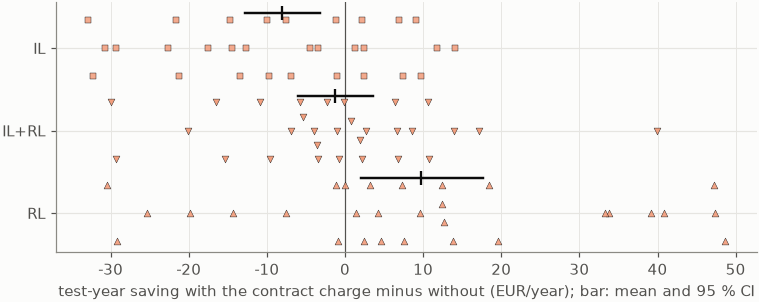

         contract method  n  mean  ci_lo  ci_hi  median  better      p  standing_line  p_holm
rolling 12 months     IL 30  -8.0  -12.8   -3.3    -7.3      10 0.0062           -4.7  0.0186
rolling 12 months  IL+RL 30  -1.2   -6.0    3.6    -0.9      13 0.5838            3.4  0.5838
rolling 12 months     RL 30   9.7    2.0   17.6     7.4      21 0.0185           15.6  0.0371


In [13]:
# Paired, per household: the same learner paid for the contract minus the same
# learner paid for the settled bill only, on the TEST year of the same
# contract. Wilcoxon signed-rank via the study's own `paired_comparison`,
# Holm over the methods of one contract type.
GAIN_ROWS = []
for contract in [c for c in [c for c in FAMILIES["power"] if c != STUDY] if "contract" in rc.arms_for(c)]:
    sub = RES[RES.contract == contract]
    wide = sub.pivot_table(index="ident", columns=["method", "arm"],
                           values="saving_total")
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
    stats = []
    for i, m in enumerate(METHODS):
        if (m, "contract") not in wide or (m, "excess") not in wide:
            continue
        pair = pd.DataFrame({"a": wide[(m, "contract")], "b": wide[(m, "excess")]}).dropna()
        d = (pair.a - pair.b).to_numpy()
        r = hs.paired_comparison(pair, "a", "b")
        lo, hi = fs.boot_ci(d, stat=np.mean)
        stats.append({"contract": TYPE_NAME[contract], "method": METHOD_NAME[m], "n": len(d),
                      "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                      "median": r["median_diff"], "better": r["n_a_greater"],
                      "p": r["p_value"],
                      "standing_line": float((sub[(sub.method == m) & (sub.arm == "contract")]
                                              .set_index("ident").saving_fixed
                                              - sub[(sub.method == m) & (sub.arm == "excess")]
                                              .set_index("ident").saving_fixed).mean())})
        col = fs.ctrl_color("SI", f"{m}_fc_h24")
        ax.scatter(d, i + fs.beeswarm(d), marker=fs.ctrl_marker(f"{m}_fc_h24"), s=20,
                   color=col, edgecolor=INK, lw=0.3, alpha=0.9, zorder=3)
        ax.plot([lo, hi], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([d.mean()], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    for s_, p_h in zip(stats, fs.holm([s_["p"] for s_ in stats])):
        s_["p_holm"] = p_h
    GAIN_ROWS += stats
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([METHOD_NAME[m] for m in METHODS])
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(pf.PLAIN)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: what the contract charge "
                     f"adds to each learner",
           xlabel=f"test-year saving with the contract charge minus without ({UNIT}); "
                  f"bar: mean and 95 % CI", ylabel="")
    pf.show(fig, f"rlc_gain_{contract}")

GAIN = pd.DataFrame(GAIN_ROWS)
GAINS = pd.concat([globals().get('GAINS', pd.DataFrame()), GAIN], ignore_index=True)
with pd.option_context("display.width", 200):
    print(GAIN.round({"mean": 1, "ci_lo": 1, "ci_hi": 1, "median": 1,
                      "standing_line": 1, "p": 4, "p_holm": 4}).to_string(index=False))

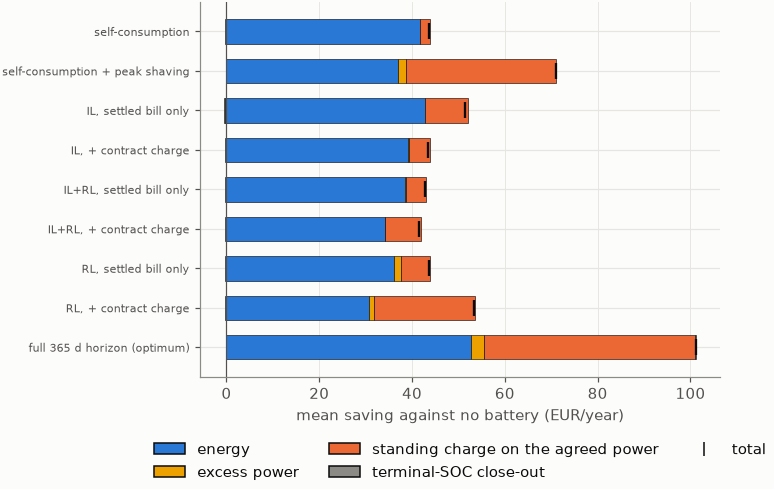

rolling 12 months: mean saving by line, EUR/year
                                 energy  power  standing  closeout  total    efc
self-consumption                   41.6   -0.1       2.3      -0.3   43.6   72.4
self-consumption + peak shaving    37.0    1.7      32.3      -0.1   70.9   72.6
IL, settled bill only              42.9   -0.2       9.2      -0.3   51.5   92.8
IL, + contract charge              39.0    0.2       4.5      -0.3   43.5   85.1
IL+RL, settled bill only           38.4    0.3       4.3      -0.3   42.8   90.4
IL+RL, + contract charge           34.1    0.1       7.7      -0.3   41.6  101.0
RL, settled bill only              36.1    1.5       6.4      -0.3   43.7  134.9
RL, + contract charge              30.6    1.1      21.9      -0.3   53.4  138.5
full 365 d horizon (optimum)       52.6    2.8      45.6       0.3  101.3  153.2 



In [14]:
# Where each controller's saving comes from, by bill line. The standing-charge
# line is the one the contract charge was written to move.
LINES_ORDER = ["energy", "power", "standing", "closeout"]
for contract in [c for c in [c for c in FAMILIES["power"] if c != STUDY] if "contract" in rc.arms_for(c)]:
    best_rule = (SUMMARY[contract].drop(index=[c for c in SUMMARY[contract].index
                                               if ":" in c or c in ("milp_full", "price_oracle")])
                 ["mean"].idxmax())
    rows = (["self_consumption", best_rule]
            + [f"{m}:{a}" for m in METHODS for a in ("excess", "contract")]
            + ["milp_full"])
    rows = list(dict.fromkeys(r for r in rows if r in SUMMARY[contract].index))
    means = (RANK[(RANK.contract == contract)].groupby("controller")[LINES_ORDER]
             .mean().reindex(rows))
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.05 * len(rows)))
    y = np.arange(len(rows))
    pos = np.zeros(len(rows))
    neg = np.zeros(len(rows))
    for name in LINES_ORDER:
        v = means[name].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.barh(y, v, left=base, color=LINE_COLOR[name], edgecolor=INK, lw=0.4,
                height=0.62)
        pos += np.clip(v, 0, None)
        neg += np.clip(v, None, 0)
    tot = means.sum(axis=1).to_numpy()
    ax.scatter(tot, y, marker="|", s=120, color=INK, zorder=4)
    ax.set_yticks(y)
    ax.set_yticklabels([label(c) for c in rows], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.xaxis.set_major_formatter(EUR)
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Patch(facecolor=LINE_COLOR[n], edgecolor=INK, label=LINE_NAME[n])
                       for n in LINES_ORDER]
                  + [Line2D([], [], marker="|", ls="", color=INK, markersize=9,
                            label="total")], where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: saving by bill line",
           xlabel=f"mean saving against no battery ({UNIT})", ylabel="")
    pf.show(fig, f"rlc_lines_{contract}")
    print(f"{TYPE_NAME[contract]}: mean saving by line, {UNIT}")
    out = means.assign(total=tot,
                       efc=RANK[RANK.contract == contract].groupby("controller")["efc"]
                       .mean().reindex(rows))
    out.index = [label(c).replace("\n", " ") for c in out.index]
    print(out.round(1).to_string(), "\n")

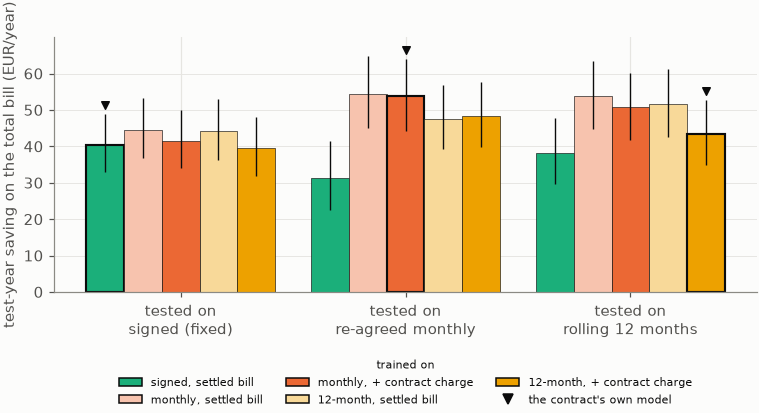

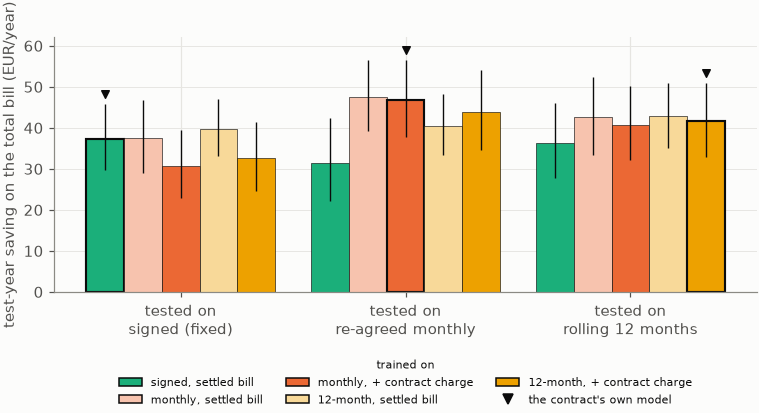

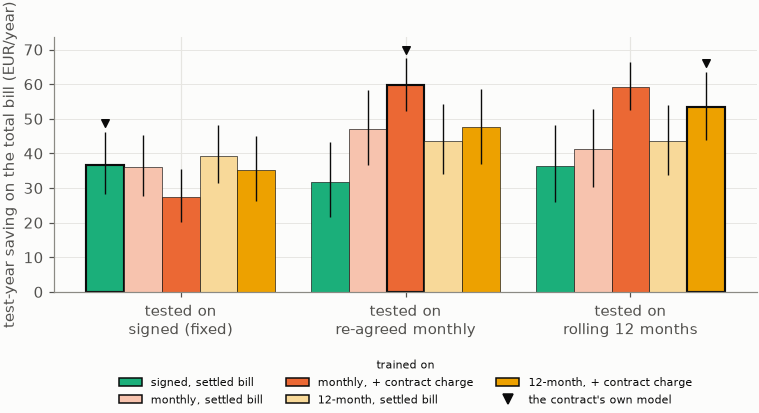


IL: mean test-year saving on the total bill, EUR/year (rows: trained on; columns: tested on)
tested_on                             fixed  monthly  annual
signed (fixed), settled bill only      40.5     31.3    38.1
re-agreed monthly, settled bill only   44.5     54.5    54.0
re-agreed monthly, + contract charge   41.6     53.7    50.7
rolling 12 months, settled bill only   44.2     47.6    51.5
rolling 12 months, + contract charge   39.5     48.3    43.5

IL+RL: mean test-year saving on the total bill, EUR/year (rows: trained on; columns: tested on)
tested_on                             fixed  monthly  annual
signed (fixed), settled bill only      37.2     31.5    36.3
re-agreed monthly, settled bill only   37.6     47.5    42.6
re-agreed monthly, + contract charge   30.8     46.8    40.8
rolling 12 months, settled bill only   39.8     40.5    42.8
rolling 12 months, + contract charge   32.5     44.0    41.6

RL: mean test-year saving on the total bill, EUR/year (rows: trained on; col

In [15]:
# Every model on every contract type's TEST year. A model is (the contract it
# was trained on, the reward it was trained with); a group of bars is one test
# contract. The marked bar is the contract's OWN model: trained on that
# contract with the reward that is its bill (`rc.SPECIALIST`).
FAM = "power"
TYPES = FAMILIES[FAM]
MODELS = [(t, a) for t in TYPES for a in rc.arms_for(t)]


def model_name(trained, arm):
    return f"{LABEL[FAM][trained]}, {ARM_NAME[arm]}"


def model_color(trained, arm):
    return CONTRACT_COLOR[trained] if arm == rc.SPECIALIST[trained] or trained == "fixed" \
        else pf.mix(CONTRACT_COLOR[trained], "#ffffff", 0.6)


if CROSS.empty or not set(TYPES) <= set(CROSS.tested_on) & set(CROSS.trained_on):
    print("cross-evaluation incomplete for this family: "
          "`python3 run_rl_contract.py cross --jobs 12`")
else:
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                    & CROSS.tested_on.isin(TYPES)]
        fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.5))
        x = np.arange(len(TYPES))
        w = 0.84 / len(MODELS)
        for k, (trained, arm) in enumerate(MODELS):
            xs = x + (k - (len(MODELS) - 1) / 2) * w
            for j, tested in enumerate(TYPES):
                v = sub[(sub.trained_on == trained) & (sub.arm == arm)
                        & (sub.tested_on == tested)].saving_total.to_numpy()
                if not len(v):
                    continue
                lo, hi = fs.boot_ci(v, stat=np.mean)
                own = trained == tested and arm == rc.SPECIALIST[tested]
                ax.bar(xs[j], v.mean(), width=w, color=model_color(trained, arm),
                       edgecolor=INK, lw=(1.4 if own else 0.4), zorder=2)
                ax.vlines(xs[j], lo, hi, color=INK, lw=0.9, zorder=3)
                if own:
                    ax.scatter([xs[j]], [hi + 2.5], marker="v", s=24, color=INK, zorder=4)
        ax.set_xticks(x)
        ax.set_xticklabels([f"tested on\n{LABEL[FAM][c]}" for c in TYPES])
        ax.yaxis.set_major_formatter(EUR)
        ax.grid(axis="y", color=pf.GRID, lw=0.6)
        ax.set_axisbelow(True)
        pf.key_legend(ax, [Patch(facecolor=model_color(t, a), edgecolor=INK,
                                 label=f"{SHORT[FAM][t]}, {ARM_SHORT[a]}")
                           for t, a in MODELS]
                      + [Line2D([], [], marker="v", ls="", color=INK,
                                label="the contract's own model")],
                      where="below", below_in=0.62, ncol=3, title="trained on",
                      fontsize=7.5, title_fontsize=7.5)
        finish(ax, title=f"SI {METHOD_NAME[m]}: every model on every {FAMILY_NAME[FAM]}",
               xlabel="", ylabel=f"test-year saving on the total bill ({UNIT})")
        pf.show(fig, f"rlc_cross_{FAM}_{m}")

    # The matrices behind the bars.
    for m in METHODS:
        mat = (CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                     & CROSS.tested_on.isin(TYPES)]
               .pivot_table(index=["trained_on", "arm"], columns="tested_on",
                            values="saving_total").reindex(MODELS).reindex(columns=list(TYPES)))
        mat.index = [model_name(t, a) for t, a in mat.index]
        print(f"\n{METHOD_NAME[m]}: mean test-year saving on the total bill, {UNIT} "
              f"(rows: trained on; columns: tested on)")
        print(mat.round(1).to_string())

    # The question as a paired test: on each contract's test year, the
    # contract's own model minus every other model, household by household.
    XROWS = []
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)]
        for tested in TYPES:
            own = sub[(sub.tested_on == tested) & (sub.trained_on == tested)
                      & (sub.arm == rc.SPECIALIST[tested])].set_index("ident").saving_total
            for trained, arm in MODELS:
                if trained == tested and arm == rc.SPECIALIST[tested]:
                    continue
                other = sub[(sub.tested_on == tested) & (sub.trained_on == trained)
                            & (sub.arm == arm)].set_index("ident").saving_total
                pair = pd.DataFrame({"own": own, "other": other}).dropna()
                if pair.empty:
                    continue
                r = hs.paired_comparison(pair, "own", "other")
                d = (pair.own - pair.other).to_numpy()
                lo, hi = fs.boot_ci(d, stat=np.mean)
                XROWS.append({"method": METHOD_NAME[m],
                              "tested_on": LABEL[FAM][tested],
                              "instead_of": model_name(trained, arm), "n": len(d),
                              "mean": d.mean(), "ci_lo": lo, "ci_hi": hi,
                              "own_better": r["n_a_greater"], "p": r["p_value"]})
    XT = pd.DataFrame(XROWS)
    XTS = dict(globals().get('XTS', {}), **{FAM: XT})
    XT["p_holm"] = np.nan
    for m in XT.method.unique():
        sel = XT.method == m
        XT.loc[sel, "p_holm"] = fs.holm(XT.loc[sel, "p"].tolist())
    with pd.option_context("display.width", 220, "display.max_rows", 100):
        print(f"\nthe contract's own model minus another model ({UNIT}; "
              f"positive = the own model saves more; Holm within a method):")
        print(XT.round({"mean": 1, "ci_lo": 1, "ci_hi": 1, "p": 4, "p_holm": 4})
              .to_string(index=False))

mean over households and the three agreed-power rules, EUR/year:
method                                             IL  IL+RL    RL
policy                                                            
a model per agreed-power rule                    45.9   41.9  49.9
two models, by reward                            48.3   41.6  51.8
one model: signed (fixed), settled bill only     36.6   35.0  35.0
one model: re-agreed monthly, settled bill only  51.0   42.5  41.4
one model: re-agreed monthly, + contract charge  48.7   39.4  48.8
one model: rolling 12 months, settled bill only  47.7   41.0  42.2
one model: rolling 12 months, + contract charge  43.7   39.4  45.4


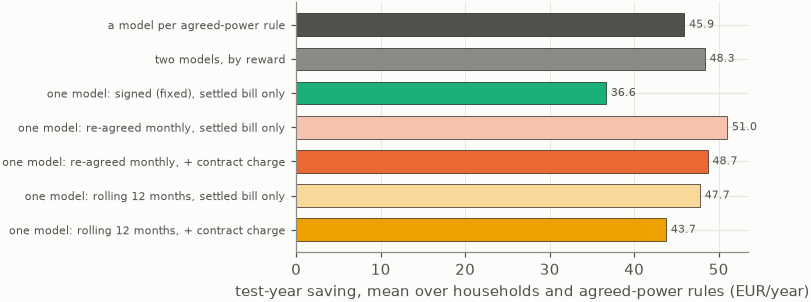

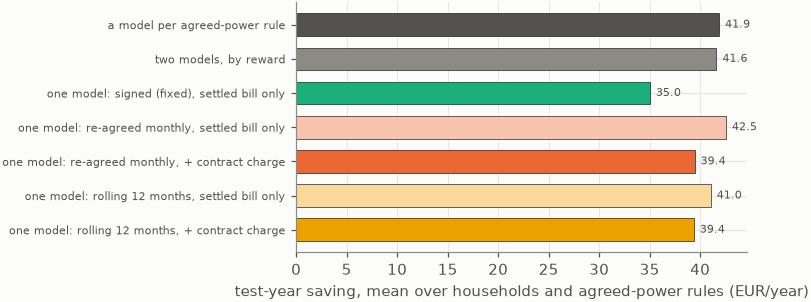

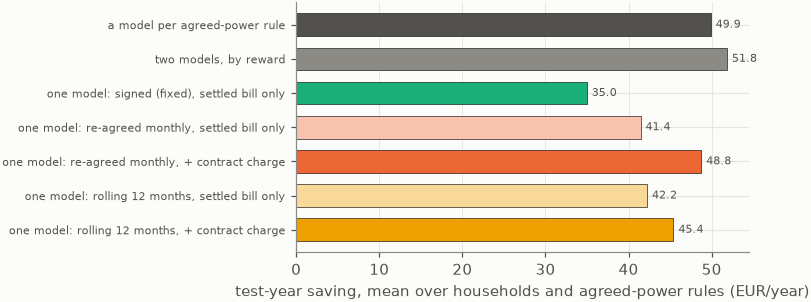

In [16]:
# Three ways to equip a household that could be on any of the three contracts:
#   per contract   each contract's own model (its own reward, trained on it)
#   by reward      (agreed-power rules only) TWO models, split by whether the
#                  dispatch moves the contract: the monthly contract-charge
#                  model wherever it does, the signed contract's own model
#                  where it does not
#   one model      a single model everywhere (every candidate is shown)
FAM = "power"
TYPES = FAMILIES[FAM]
MODELS = [(t, a) for t in TYPES for a in rc.arms_for(t)]
if not CROSS.empty and set(TYPES) <= set(CROSS.tested_on) & set(CROSS.trained_on):
    rows = []
    for m in METHODS:
        sub = CROSS[(CROSS.method == m) & CROSS.trained_on.isin(TYPES)
                    & CROSS.tested_on.isin(TYPES)]
        cell = sub.pivot_table(index=["trained_on", "arm"], columns="tested_on",
                               values="saving_total")
        per = np.mean([cell.loc[(c, rc.SPECIALIST[c]), c] for c in TYPES])
        rows.append({"method": METHOD_NAME[m],
                     "policy": f"a model per {FAMILY_NAME[FAM]}",
                     "saving": per, "kind": "per"})
        if FAM == "power":
            two = np.mean([cell.loc[("fixed", "excess"), "fixed"]]
                          + [cell.loc[("monthly", "contract"), c]
                             for c in ("monthly", "annual")])
            rows.append({"method": METHOD_NAME[m], "policy": "two models, by reward",
                         "saving": two, "kind": "two"})
        for t, a in MODELS:
            rows.append({"method": METHOD_NAME[m], "policy": "one model: " + model_name(t, a),
                         "saving": cell.loc[(t, a), list(TYPES)].mean(),
                         "kind": "one", "model": (t, a)})
    POLICY = pd.DataFrame(rows)
    POLICIES = dict(globals().get("POLICIES", {}), **{FAM: POLICY})
    print(f"mean over households and the three {FAMILY_NAME[FAM]}s, {UNIT}:")
    print(POLICY.pivot(index="policy", columns="method", values="saving")
          .reindex(POLICY.policy.drop_duplicates())[[METHOD_NAME[m] for m in METHODS]]
          .round(1).to_string())

    for m in METHODS:
        d = POLICY[POLICY.method == METHOD_NAME[m]].reset_index(drop=True)
        fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.42))
        y = np.arange(len(d))
        cols = [INK_2 if k == "per" else MUTED if k == "two" else model_color(*mod)
                for k, mod in zip(d.kind, d.get("model", [None] * len(d)))]
        ax.barh(y, d.saving, color=cols, edgecolor=INK, lw=0.4, height=0.66)
        for yi, v in zip(y, d.saving):
            ax.text(v + 0.6, yi, f"{v:.1f}", va="center", fontsize=7.5, color=INK_2)
        ax.set_yticks(y)
        ax.set_yticklabels(d.policy, fontsize=7.5)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(EUR)
        ax.grid(axis="x", color=pf.GRID, lw=0.6)
        ax.set_axisbelow(True)
        finish(ax, title=f"SI {METHOD_NAME[m]}: how many models, across {FAMILY_NAME[FAM]}s",
               xlabel=f"test-year saving, mean over households and {FAMILY_NAME[FAM]}s ({UNIT})",
               ylabel="")
        pf.show(fig, f"rlc_separate_models_{FAM}_{m}")

## 6. Hyperparameter search under the contract reward

Every learned controller above was trained with the panel's hyperparameters
(`run_rl_benchmark.TUNED`), and those were searched under the *old* reward — an objective that
could not see the standing charge. This is the same search run again under the new one
(`run_rl_hpo.py all --reward contract`), for the two learners the reward reaches: the DQN
(RL) and the fine-tune of the clone (IL+RL). The clone itself has no reward to search under.

Same protocol as `FIGURES_RL_HPO.ipynb`, on the study's contract:

- **Search** — 40 trials per learner (TPE, median pruning after 3 of 8 households), on 8
  households that are **not** study units, training blocks only, scored on the 20 held-out
  weeks with the contract-aware validation of section 2. The space is the earlier search's
  plus the reward's own dial (`weight`, 0.25–4) and episodes up to 28 days — under this
  reward an episode is billed as a share of a month, so its length is how much of a month
  the agent answers for at once. Trial 0 is the panel's settings.
- **Refine** — the panel's settings and the three best trials under three seeds, same
  households. The winner is the best seed average.
- **Confirm** — winner and panel's settings on the **30 study households**, test year, three
  seeds, both trained with the contract charge. A verdict; nothing reads it back.

5.5 hours on 13 workers, no failed evaluation.

**The search found nothing.** Read the first figures as a null result:

- **RL.** 27 complete trials, 13 pruned. The best single draw is 1.1 EUR/a above the
  panel's settings on validation; refined over three seeds the winner is **+0.9** (3 of 8
  households better, p 0.95). The sampler converged back onto the panel's own region —
  learning rate 1.1e-4 against 1.2e-4, the same n-step, width and target sync — and moved
  `weight` to 0.85.
- **IL+RL.** 18 complete, 22 pruned. Best draw +4.4, refined winner **+3.2** (4 of 8, p 0.46),
  with `weight` at 2.0, a longer horizon (γ 0.999) and more of the clone in the exploration.
- **The reward's weight is not a lever.** It carries 9 % of the variance for IL+RL and less
  than 4 % for RL (what matters is γ and the learning rate for RL, how fast the clone's pull
  decays for IL+RL), and the two winners sit on opposite sides of 1. That is section 2's
  finding again, now with every other setting free to move with it.

**On the test year the tuned RL settings are worse.** Three seeds, 30 households, paired:

| | tuned minus panel's settings | |
|---|---|---|
| RL | **−10.2 EUR/a** [−14.0, −6.5] | 6 of 30 better, p < 0.001; cycles 139 EFC/a against 156 |
| IL+RL | +1.1 EUR/a [−3.3, +4.7] | 19 of 30 better, p 0.06 |

A configuration that led by 0.9 EUR/a on eight validation households loses 10 on the thirty
it was never fitted to. Picking the top of forty noisy draws selects noise. A plausible
reason it also had a direction, though not a tested one: the winner trains on 7-day episodes
instead of 14 and discounts faster (γ 0.9966 against 0.9987), both of which shorten how far
ahead the agent is paid to keep a contract line — cheap on validation weeks that share a
contract with the training weeks around them, expensive on a year it has to hold the line
alone. **The panel's settings stay, for both learners; nothing is promoted.** (`run_rl_hpo.py report --reward contract`
prints the winners in `TUNED` form for the record.)

**What the three seeds say about the contract charge itself.** The confirmation trained the
panel's settings with the contract charge under seeds 0, 1 and 2; the earlier search holds
the same three seeds on the settled bill. Paired, on the test year:

| | contract charge minus settled bill, three seeds | by seed |
|---|---|---|
| RL | **+7.9 EUR/a** [3.2, 12.6], 21 of 30, p_holm 0.02 | +12.2, +7.8, +3.8 |
| IL+RL | +0.9 EUR/a [−2.5, 4.4], 17 of 30, not significant | −1.4, +2.0, +2.2 |

So the headline of section 3 holds and shrinks: the gain is positive under every seed and
significant on their average, and seed 0 — the panel's, and the one every other figure in
this notebook shows — was the most favourable of the three. Seed-averaged, RL with the
contract charge saves 57.2 EUR/a on the study's contract (3 of 30 households ahead of the
best rule), against 72.2 for `self-consumption + peak shaving`.

driver: not running
             study  households  complete  pruned  failed  running  waiting  incumbent_val  best_val   winner  winner_delta_val  confirmed_rows
SI_bc_dqn_contract           8        18      22       0        0        0          71.43     75.80 trial 38              3.23             180
   SI_dqn_contract           8        27      13       0        0        0          67.65     68.74 trial 12              0.92             180


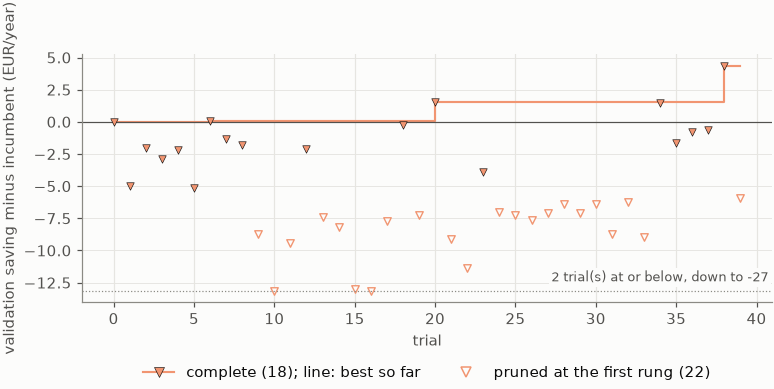

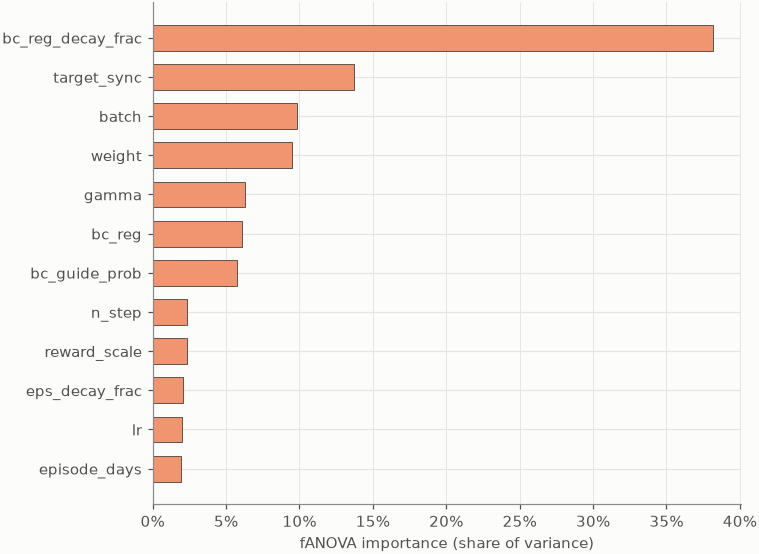

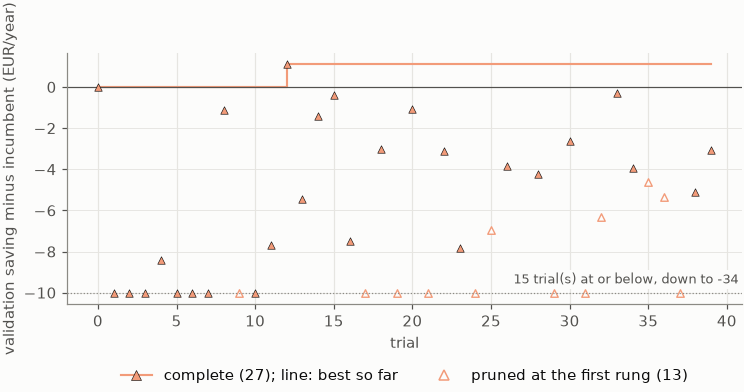

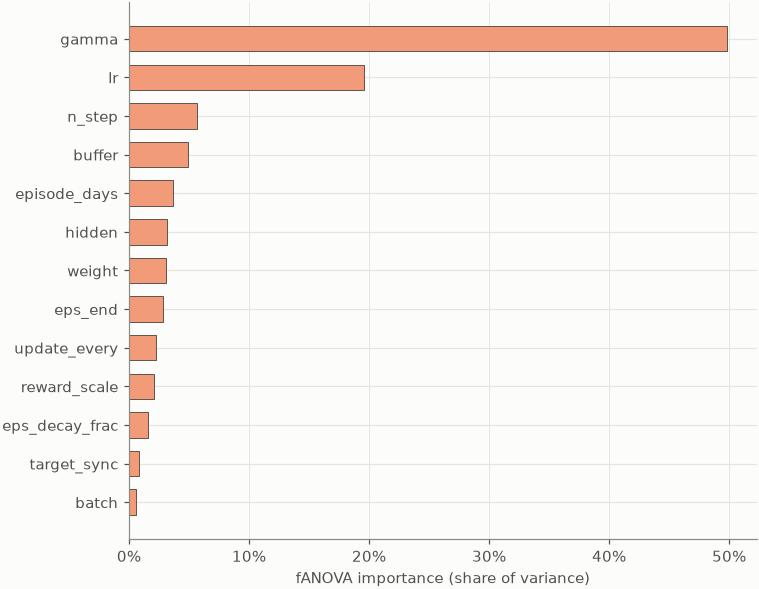

In [17]:
# The search under the contract reward (`run_rl_hpo.py all --reward contract`).
# Everything in this cell is VALIDATION on households that are not study units.
HROOT = hpo.CONTRACT_ROOT
HSTUDIES = hpo.list_studies(HROOT)
HDRIVER = hpo.driver_running(HROOT)
print("driver:", f"RUNNING since {HDRIVER['started']} -- this is a snapshot" if HDRIVER
      else "not running")
HSTATUS = hpo.status_frame(HROOT)
if HSTATUS.empty:
    print("no studies yet: `python3 run_rl_hpo.py all --reward contract --jobs 12`")
else:
    with pd.option_context("display.width", 220):
        print(HSTATUS.round(2).to_string(index=False))

for name in HSTUDIES:
    s = hpo.read_settings(name, HROOT)
    m = s["method"]
    h = hpo.history_frame(name, HROOT)
    if h.empty:
        print(f"{name}: no finished trials yet")
        continue
    col = fs.ctrl_color("SI", f"{m}_fc_h24")
    floor = -max(3.0 * float(np.nan_to_num(h.best.abs().max())), 10.0)
    y = h.delta.clip(lower=floor)
    comp, prun = h.state == "COMPLETE", h.state == "PRUNED"
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.45))
    ax.scatter(h.number[comp], y[comp], marker=fs.ctrl_marker(f"{m}_fc_h24"), s=24,
               color=col, edgecolor=INK, lw=0.4, zorder=3)
    ax.scatter(h.number[prun], y[prun], marker=fs.ctrl_marker(f"{m}_fc_h24"), s=24,
               facecolor=SURFACE, edgecolor=col, lw=0.9, zorder=2)
    ax.step(h.number, h.best, where="post", color=col, lw=1.4, zorder=1)
    below = int((h.delta < floor).sum())
    if below:
        ax.axhline(floor, color=MUTED, lw=0.8, ls=":")
        pf.edge_label(ax, floor, f"{below} trial(s) at or below, down to "
                                 f"{h.delta.min():,.0f}", side="right")
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.grid(axis="y", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, [Line2D([], [], marker=fs.ctrl_marker(f"{m}_fc_h24"), color=col,
                              lw=1.4, markeredgecolor=INK, markeredgewidth=0.4,
                              label=f"complete ({int(comp.sum())}); line: best so far"),
                       Line2D([], [], marker=fs.ctrl_marker(f"{m}_fc_h24"), ls="",
                              markerfacecolor=SURFACE, markeredgecolor=col,
                              label=f"pruned at the first rung ({int(prun.sum())})")],
                  where="below", below_in=0.5, ncol=2)
    finish(ax, title=f"SI {METHOD_NAME[m]}, contract reward: search progress against "
                     f"the panel's settings",
           xlabel="trial", ylabel=f"validation saving minus incumbent ({UNIT})")
    pf.show(fig, f"rlc_hpo_history_{m}")

    try:
        imp = hpo.importance_frame(name, HROOT)
    except Exception as exc:
        imp = pd.DataFrame()
        print(f"{name}: importance not computable ({exc})")
    if not imp.empty:
        imp = imp.sort_values("importance")
        fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.045 * len(imp)))
        ax.barh(imp.param, 100 * imp.importance, color=col, edgecolor=INK, lw=0.4,
                height=0.66)
        ax.xaxis.set_major_formatter(pf.PCT)
        ax.grid(axis="x", color=pf.GRID, lw=0.6)
        ax.set_axisbelow(True)
        finish(ax, title=f"SI {METHOD_NAME[m]}, contract reward: what the validation "
                         f"saving depends on",
               xlabel="fANOVA importance (share of variance)", ylabel="")
        pf.show(fig, f"rlc_hpo_importance_{m}")


SI_bc_dqn_contract: winner trial 38 -- validation 72.4 EUR/year against 69.1 for the panel's settings (delta +3.2, 4/8 households, p 0.461; seeds [0, 1, 2])
                      panel     winner changed
setting                                       
lr                0.0009171 0.00071393       *
gamma               0.99503    0.99885       *
n_step                    8          1       *
batch                   128         64       *
target_sync            2000       2000        
eps_decay_frac      0.30221    0.18412       *
reward_scale         10.639     11.729       *
bc_reg              0.48029    0.65135       *
bc_reg_decay_frac   0.52676    0.30862       *
bc_guide_prob       0.25518    0.52107       *
weight                    1     1.9801       *
episode_days              7          7        


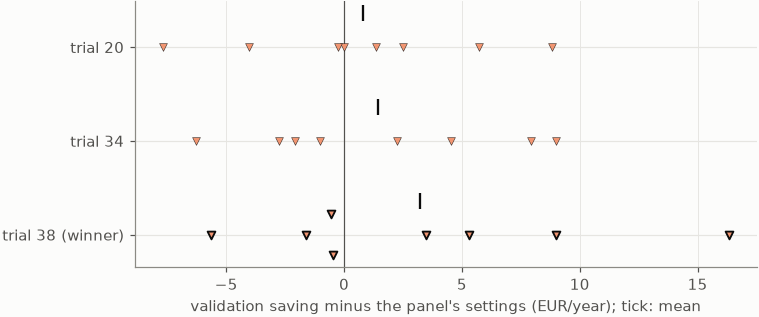


SI_dqn_contract: winner trial 12 -- validation 66.3 EUR/year against 65.4 for the panel's settings (delta +0.9, 3/8 households, p 0.945; seeds [0, 1, 2])
                    panel     winner changed
setting                                     
lr             0.00011837 0.00011072       *
gamma             0.99869    0.99664       *
n_step                  4          4        
batch                 128        128        
hidden                256        256        
target_sync          5000       5000        
update_every            4          1       *
buffer              2e+05      4e+05       *
eps_end          0.093137   0.083375       *
eps_decay_frac    0.29819    0.21554       *
reward_scale       79.083     64.911       *
episode_days           14          7       *
weight                  1     0.8519       *


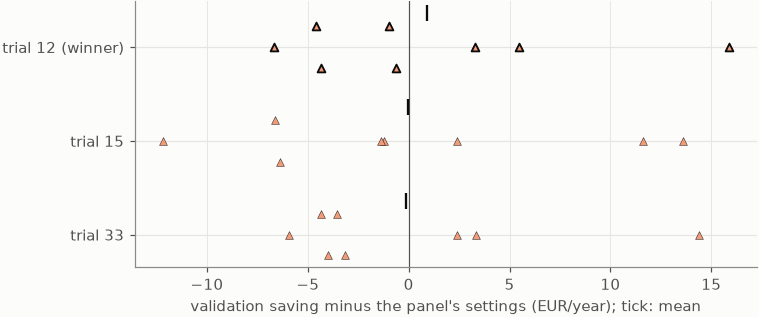

In [18]:
# Refine: the incumbent and the three best trials under three seeds, on the
# search households. Still validation only.
WINNERS = {}
for name in HSTUDIES:
    w = hpo.winner(name, HROOT)
    if w is None:
        print(f"{name}: no winner yet (search or refine still to run)")
        continue
    WINNERS[name] = w
    s = hpo.read_settings(name, HROOT)
    m = s["method"]
    inc = s["incumbent"]
    print(f"\n{name}: winner {w['label']} -- validation {w['mean_saving_val_a']:.1f} "
          f"{UNIT} against {w['incumbent_saving_val_a']:.1f} for the panel's settings "
          f"(delta {w['delta_vs_incumbent']:+.1f}, {w['n_better']}/{len(w['households'])} "
          f"households, p {w['p_vs_incumbent']:.3f}; seeds {w['seeds']})")
    rows = [{"setting": k, "panel": inc.get(k), "winner": w["overrides"].get(k)}
            for k, _, _ in [tuple(x) for x in s["space"]]]
    t = pd.DataFrame(rows).set_index("setting")
    t["changed"] = [("" if a == b else "*") for a, b in zip(t.panel, t.winner)]
    with pd.option_context("display.float_format", lambda v: f"{v:.5g}"):
        print(t.to_string())

    rf = hpo.refine_frame(name, HROOT)
    wide = rf.pivot(index="ident", columns="label", values="saving_val_a")
    cands = [c for c in wide.columns if c != "incumbent"]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.08 * len(cands)))
    col = fs.ctrl_color("SI", f"{m}_fc_h24")
    for i, c in enumerate(cands):
        d = (wide[c] - wide["incumbent"]).to_numpy()
        ax.scatter(d, i + fs.beeswarm(d, height=0.22), marker=fs.ctrl_marker(f"{m}_fc_h24"),
                   s=26, color=col, edgecolor=INK, lw=(1.2 if c == w["label"] else 0.3),
                   zorder=3)
        ax.scatter([d.mean()], [i - 0.36], marker="|", s=110, color=INK, zorder=4)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_yticks(range(len(cands)))
    ax.set_yticklabels([c + (" (winner)" if c == w["label"] else "") for c in cands])
    ax.invert_yaxis()
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title=f"SI {METHOD_NAME[m]}, contract reward: the refined candidates "
                     f"against the panel's settings",
           xlabel=f"validation saving minus the panel's settings ({UNIT}); tick: mean",
           ylabel="")
    pf.show(fig, f"rlc_hpo_refine_{m}")

winner minus the panel's settings, test year (lower bill + wear; EUR/year, seed-averaged per household):
             study tariff method  n  seeds    gain      lo     hi     p  n_better  efc_current  efc_winner  p_holm
SI_bc_dqn_contract     SI bc_dqn 30      3   1.092  -3.261  4.717 0.064        19      107.799     110.368   0.064
   SI_dqn_contract     SI    dqn 30      3 -10.247 -13.962 -6.493 0.000         6      155.876     138.961   0.000


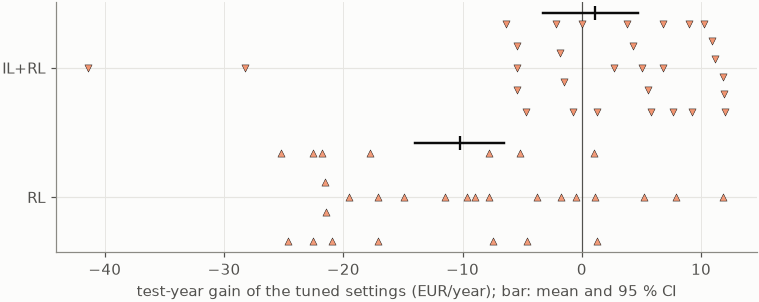


contract charge against the settled bill, three seeds, test year (EUR/year; positive = the contract-charge model's household pays less):
method contract-charge model  n  seeds  gain  ci_lo  ci_hi  better      p           by seed  p_holm
 IL+RL                 tuned 30      3   2.0   -3.8    6.8      20 0.0523  +1.5, +2.8, +1.7  0.1568
 IL+RL      panel's settings 30      3   0.9   -2.5    4.4      17 0.4400  -1.4, +2.0, +2.2  0.6775
    RL                 tuned 30      3  -2.3   -6.5    1.9      12 0.3387  -1.5, -0.0, -5.3  0.6775
    RL      panel's settings 30      3   7.9    3.2   12.6      21 0.0047 +12.2, +7.8, +3.8  0.0187

test-year saving on the total bill, three seeds averaged (EUR/year):
                            controller  saving  ahead of best rule
    MILP, full 365 d horizon (optimum)   108.3                 NaN
  RBC: self-consumption + peak shaving    72.2                 NaN
   RL, contract charge, panel settings    57.2                 3.0
         IL+RL, contract

In [19]:
# Confirm: the winner against the panel's settings, BOTH trained with the
# contract charge, on the 30 study households' TEST year, three seeds. A
# verdict -- nothing reads it back into a choice.
CONFIRM = hpo.confirm_summary(HSTUDIES, root=HROOT) if HSTUDIES else pd.DataFrame()
if CONFIRM.empty:
    print("no test-year confirmation yet")
else:
    with pd.option_context("display.width", 220):
        print("winner minus the panel's settings, test year (lower bill + wear; "
              f"{UNIT}, seed-averaged per household):")
        print(CONFIRM.drop(columns=["d"]).round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.2 + 0.11 * len(CONFIRM)))
    for i, r in CONFIRM.reset_index(drop=True).iterrows():
        d = np.asarray(r["d"], dtype=float)
        key = f"{r['method']}_fc_h24"
        ax.scatter(d, i + fs.beeswarm(d), marker=fs.ctrl_marker(key), s=22,
                   color=fs.ctrl_color("SI", key), edgecolor=INK, lw=0.3, zorder=3)
        ax.plot([r["lo"], r["hi"]], [i - 0.42, i - 0.42], color=INK, lw=1.6, zorder=4)
        ax.scatter([r["gain"]], [i - 0.42], marker="|", s=90, color=INK, zorder=5)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_yticks(range(len(CONFIRM)))
    ax.set_yticklabels([METHOD_NAME[m] for m in CONFIRM.method])
    ax.invert_yaxis()
    ax.grid(axis="x", color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    finish(ax, title="SI, contract reward: tuned settings against the panel's, test year",
           xlabel=f"test-year gain of the tuned settings ({UNIT}); bar: mean and 95 % CI",
           ylabel="")
    pf.show(fig, "rlc_hpo_confirm")

# The contract charge itself, now on THREE seeds: the contract study's runs at
# the panel's settings ("current" above) against the panel's own settings on
# the settled bill, whose three seeds the earlier search confirmed
# (results_local/rl_hpo, its "winner" rows -- the settings since promoted).
SEEDS3 = []
for name in HSTUDIES:
    m = hpo.read_settings(name, HROOT)["method"]
    new = hpo.confirm_frame(name, HROOT)
    old = hpo.confirm_frame(f"SI_{m}")
    if new.empty or old.empty:
        continue
    for which, frame in (("tuned", new[new.label == "winner"]),
                         ("panel's settings", new[new.label == "current"])):
        a = frame.groupby("ident")["test_net"].mean()
        b = old[old.label == "winner"].groupby("ident")["test_net"].mean()
        pair = pd.DataFrame({"contract": a, "settled": b}).dropna()
        if len(pair) < 6:
            continue
        d = (pair.settled - pair.contract).to_numpy()
        r = hs.paired_comparison(pair, "settled", "contract")
        lo, hi = fs.boot_ci(d, stat=np.mean)
        per_seed = [float((old[(old.label == "winner") & (old.seed == sd)].set_index("ident").test_net
                           - frame[frame.seed == sd].set_index("ident").test_net).mean())
                    for sd in sorted(frame.seed.unique())]
        SEEDS3.append({"method": METHOD_NAME[m], "contract-charge model": which,
                       "n": len(d), "seeds": int(frame.seed.nunique()),
                       "gain": d.mean(), "ci_lo": lo, "ci_hi": hi,
                       "better": int((d > 0).sum()), "p": r["p_value"],
                       "by seed": ", ".join(f"{v:+.1f}" for v in per_seed)})
if SEEDS3:
    S3 = pd.DataFrame(SEEDS3)
    S3["p_holm"] = fs.holm(S3.p.tolist())
    with pd.option_context("display.width", 220):
        print(f"\ncontract charge against the settled bill, three seeds, test year ({UNIT}; "
              f"positive = the contract-charge model's household pays less):")
        print(S3.round({"gain": 1, "ci_lo": 1, "ci_hi": 1, "p": 4, "p_holm": 4})
              .to_string(index=False))

# Where the tuned models stand against the rules, on the total bill.
if not CONFIRM.empty:
    nb = (rc.load_refs().query("contract == @STUDY").pivot(index="ident", columns="controller",
                                                           values="cost_eur_total"))
    nb.index = nb.index.astype(int)
    rows = []
    for name in HSTUDIES:
        m = hpo.read_settings(name, HROOT)["method"]
        cf = hpo.confirm_frame(name, HROOT)
        for which in ("winner", "current"):
            g = cf[cf.label == which].groupby("ident")["cost_eur_total"].mean()
            rows.append({"controller": f"{METHOD_NAME[m]}, contract charge, "
                                       f"{'tuned' if which == 'winner' else 'panel settings'}",
                         "saving": float((nb["no_battery"].reindex(g.index) - g).mean()),
                         "ahead of best rule": int((g < nb["self_consumption_peak_shaving"]
                                                    .reindex(g.index)).sum())})
    for c in ("self_consumption_peak_shaving", "self_consumption", "milp_full"):
        rows.append({"controller": hs.controller_label(c, 48, n_sim=365),
                     "saving": float((nb["no_battery"] - nb[c]).mean()),
                     "ahead of best rule": np.nan})
    print(f"\ntest-year saving on the total bill, three seeds averaged ({UNIT}):")
    print(pd.DataFrame(rows).sort_values("saving", ascending=False).round(1)
          .to_string(index=False))

## 7. Does validation see what the test year shows?

Every setting and every early stop in this notebook was decided on the held-out weeks, so
the measure has to track the scored year or the decisions were noise. One point per
(learner, household): the contract charge's gain on validation against its gain on the
test year, per contract type (the Spearman correlations are printed above the figures).

The agreement is positive on every contract and never strong: ρ +0.24 on the study's
contract (p 0.025), +0.29 on the 12-month rule, +0.47 on the active list, +0.14 on the
single-tariff list (not significant). On the study's contract it is clear by learner what
carries it: for **RL** validation predicted +10 EUR/a and the test year
delivered +12.6; for **IL+RL** validation predicted +7 and the test year delivered nothing.
A fine-tune starts from a clone that has memorised the training weeks — on the eight
households this was measured on, the clone saved 80 EUR/a over the two training years
against 74 for the best rule, and loses to that rule on the held-out weeks and on the test
year — and the held-out measure still shares one trajectory, and one contract, with those
training weeks. That is a limit of validating on weeks inside the training years. It is the
reason the IL+RL rows in section 2 are weaker evidence than the RL rows, and section 6 met
the same limit from the other side: a hyperparameter pick that led on validation and lost
on the test year.

Every reinforcement run behind these numbers was trained to the early-stop rule: those that
had not settled at 500k steps were re-trained at 1M, as the panel's stragglers were (20 on
the agreed-power rules, 27 on the two new price lists; one fine-tune on the single-tariff
list had still not settled at 1M).

the study's (dynamic price, re-agreed monthly): validation vs test gain, Spearman rho +0.24 [+0.02, +0.44], p 0.025, n 90


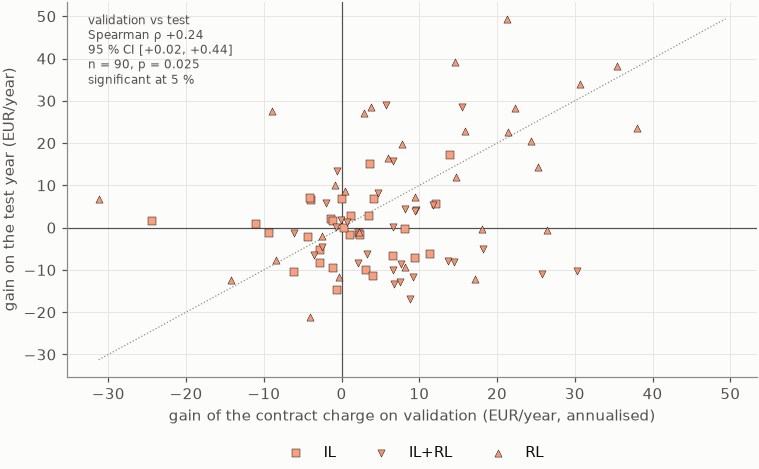

rolling 12 months: validation vs test gain, Spearman rho +0.29 [+0.09, +0.48], p 0.005, n 90


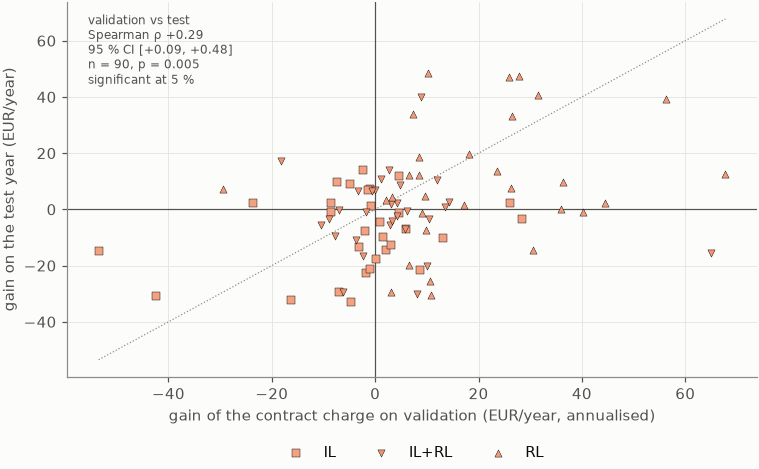

active (4-tariff) price: validation vs test gain, Spearman rho +0.47 [+0.27, +0.63], p 0.000, n 90


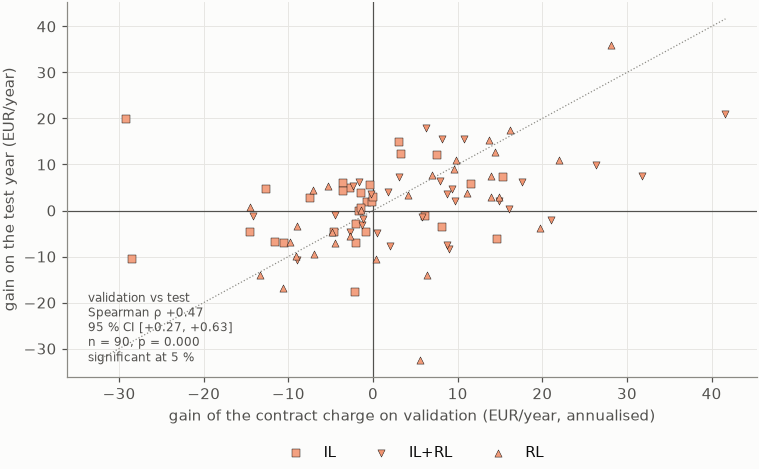

single-tariff price: validation vs test gain, Spearman rho +0.14 [-0.09, +0.35], p 0.188, n 90


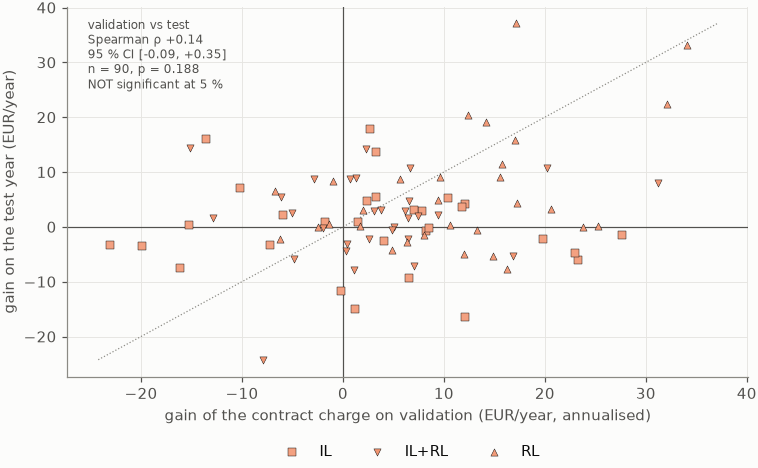

reinforcement runs: early-stop verdict, median steps, test-year cycles
                          runs  converged     steps    efc
contract arm      method                                  
active   contract bc_dqn    30         30  320000.0  195.0
                  dqn       30         30  450000.0  207.0
         excess   bc_dqn    30         30  310000.0  193.0
                  dqn       30         30  470000.0  208.0
annual   contract bc_dqn    30         30  300000.0  101.0
                  dqn       30         30  440000.0  138.0
         excess   bc_dqn    30         30  300000.0   90.0
                  dqn       30         30  380000.0  135.0
fixed    excess   bc_dqn    30         30  300000.0   92.0
                  dqn       30         30  390000.0  128.0
monthly  contract bc_dqn    30         30  320000.0  116.0
                  dqn       30         30  380000.0  146.0
         excess   bc_dqn    30         30  300000.0  101.0
                  dqn       30         30  4

In [20]:
# Does the validation measure the reward is tuned and early-stopped on agree
# with the test year it never sees? One point per (controller, household):
# validation saving against the same household's contract-blind learner,
# against the same difference on the test year.
DAYS = sum(b - a for a, b in rb.VAL_BLOCKS)
for contract in [c for c in rr.ALL_TYPES if "contract" in rc.arms_for(c)
                 and c in set(RES.contract)]:
    sub = RES[RES.contract == contract]
    fig, ax = plt.subplots(figsize=pf.figsize(ratio=0.62))
    allx, ally = [], []
    for m in METHODS:
        a = sub[(sub.method == m) & (sub.arm == "contract")].set_index("ident")
        b = sub[(sub.method == m) & (sub.arm == "excess")].set_index("ident")
        idx = a.index.intersection(b.index)
        if not len(idx):
            continue
        x = (b.loc[idx, "val_cost"] - a.loc[idx, "val_cost"]) * 365.0 / DAYS
        y = a.loc[idx, "saving_total"] - b.loc[idx, "saving_total"]
        allx += x.tolist()
        ally += y.tolist()
        ax.scatter(x, y, marker=fs.ctrl_marker(f"{m}_fc_h24"), s=22,
                   color=fs.ctrl_color("SI", f"{m}_fc_h24"), edgecolor=INK, lw=0.3,
                   label=METHOD_NAME[m], zorder=3)
    if allx:
        rho, p, lo, hi, n = fs.spearman_ci(np.array(allx), np.array(ally))
        print(f"{TYPE_NAME[contract]}: validation vs test gain, Spearman rho {rho:+.2f} "
              f"[{lo:+.2f}, {hi:+.2f}], p {p:.3f}, n {n}")
        lim = [min(allx + ally), max(allx + ally)]
        ax.plot(lim, lim, color=MUTED, lw=0.8, ls=":", zorder=1)
        fs.corner_block(ax, fs.rho_lines("validation vs test", rho, p, lo, hi, n),
                        INK_2, np.array(ally))
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.grid(color=pf.GRID, lw=0.6)
    ax.set_axisbelow(True)
    pf.key_legend(ax, ax.get_legend_handles_labels()[0], where="below", below_in=0.5, ncol=3)
    finish(ax, title=f"SI, {TYPE_NAME[contract]}: the validation gain "
                     f"against the test-year gain",
           xlabel=f"gain of the contract charge on validation ({UNIT}, annualised)",
           ylabel=f"gain on the test year ({UNIT})")
    pf.show(fig, f"rlc_val_vs_test_{contract}")

VAL_TEST = {}
conv = (RES[RES.method != "bc"].groupby(["contract", "arm", "method"])
        .agg(runs=("ident", "size"),
             converged=("train_converged", lambda s: int(s.fillna(False).astype(bool).sum())),
             steps=("train_steps", "median"), efc=("efc", "mean")))
print("reinforcement runs: early-stop verdict, median steps, test-year cycles")
print(conv.round(0).to_string())

## 8. What this does and does not show

**Shown, on 30 households, paired, corrected:**

- The SI reward was missing a bill line, and adding it is worth **+12.6 EUR/a to RL** on the
  study's contract, +9.7 on the 12-month rule and +6.3 on the single-tariff list. It is
  worth nothing on the active list and costs 9 on a signed contract.
- **Price lists need their own models**; agreed-power rules need only their own reward.
- **On the active price list the learned controllers beat every rule by 60 EUR/a** and reach
  83–84 % of the optimum. On the dynamic and single-tariff lists the best rule is still
  ahead.
- Behaviour cloning is not helped by the contract charge on any contract.
- **The panel's hyperparameters survive the new reward.** A 40-trial search per learner
  under it found nothing better, and its top RL pick is 10 EUR/a worse on the test year.
- **Over three seeds the RL gain on the study's contract is +7.9 EUR/a**, positive in each
  seed, against +12.6 on the panel's seed alone.

**Not shown, and worth saying:**

- **The rules were not re-tuned per price list.** Their parameters are the dynamic list's.
  The learned controllers' lead on the active list is over rules that were never set up for
  four posted prices.
- **One seed** outside section 6, and section 6 says what that is worth: the RL
  contract-charge gain on the study's contract is +12.6 on seed 0 and +7.9 on three. The
  single-seed gains on the 12-month rule (+9.7) and the single-tariff list (+6.3) should be
  read with the same discount; the cross-price-list effects (20–110 EUR/a) and the lead over
  the rules on the active list (60) are far outside it.
- **Where the foresight gap is.** On the dynamic list hand-built reactive policies with the
  agent's own five actions and contract state top out at the best rule's level on
  validation, so the remaining distance to the MILP (48 EUR/a) is foresight of the
  household's peaks, not something a reward can supply.
- **The signed contract's level is an assumption** (the operator's figure from the previous
  metering year).
- **GEN-I's lists only**, and the fourth self-supply list (*Fiksni*, the active list half a
  cent dearer under a tie-in) was left out as the same structure.

**Not done:** the panel (`run_rl_benchmark`), the pooled models and the earlier search still
train SI on the settled bill and the dynamic list only, so `FIGURES_RL`,
`FIGURES_RL_GLOBAL`, `FIGURES_RL_HPO` and `CODE.ipynb` are unchanged. Promoting the contract
charge there is one argument (`reward_fn`) and a retrain of the SI half; on this evidence it
is worth doing for RL and pointless for the clone. Adding the active and single-tariff lists
to `STUDY_ARMS` — so the MPC arms and the forecast questions are asked on them too — is the
larger step, and section 4 is the reason to take it.